In [ ]:
!pip install hazm
!pip install hazm emoji python-bidi arabic-reshaper
!pip install graphviz
!pip install transformers datasets accelerate
!pip install transformers datasets accelerate evaluate

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.2/887.2 kB 17.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 59.2 MB/s eta 0:00:00
  Created wheel for flashtext: filename=flashtext-2.7-py2.py3-none-any.whl size=9300 sha256=4db1e2ff339c1c6c5ef7800cca88f674c57dff158dd475e9ecd2e8b4d1b92578
  Stored in directory: /root/.cache/pip/wheels/8c/24/da/4d994d7a27cfc73a4e513a669fbeec4a71f871fe245a81977f
Successfully built flashtext
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.2/296.2 kB 16.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from bidi.algorithm import get_display
from arabic_reshaper import reshape
import re
from hazm import Normalizer, WordTokenizer , InformalNormalizer
import emoji
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from collections import Counter
from sklearn.model_selection import train_test_split
from graphviz import Digraph
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support,f1_score
import evaluate
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)


# Data Exploration:

In [ ]:
dataset_url = "https://drive.google.com/uc?export=download&id=1wWbb61fzHnV7u_rHsZGVY62v8v9X7cve"
df = pd.read_csv(dataset_url)
df_raw = df.copy()
df

,text,label,source,created_at
0,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,0,snappfood,NaN
1,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...,2,snappfood,NaN
2,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...,0,snappfood,NaN
3,عالی بود همه چه درست و به اندازه و کیفیت خوب، ...,2,snappfood,NaN
4,شیرینی وانیلی فقط یک مدل بود.,2,snappfood,NaN
...,...,...,...,...
73823,اون هایی که میگن 360 از ps3 گرافیکش بهتره معلو...,1,digikala,NaN
73824,به عنوان مثال در مدل MotorSport به غیر از خود ...,1,digikala,NaN
73825,پروبوک 4530 هم داشتم با سی پی یو core i7 اما 3...,1,digikala,NaN
73826,ولی با طراحی بی نظیرش و یا طراحی سفارشی که دار...,2,digikala,NaN


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73828 entries, 0 to 73827
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   text        73828 non-null  object 
 1   label       73828 non-null  int64  
 2   source      73828 non-null  object 
 3   created_at  0 non-null      float64
dtypes: float64(1), int64(1), object(2)
memory usage: 2.3+ MB
None


In [ ]:
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True))

label
2    37940
0    33479
1     2409
Name: count, dtype: int64
label
2    0.513897
0    0.453473
1    0.032630
Name: proportion, dtype: float64


In [ ]:
print(df['source'].value_counts())
print(df['source'].value_counts(normalize=True))

source
snappfood    65967
digikala      7861
Name: count, dtype: int64
source
snappfood    0.893523
digikala     0.106477
Name: proportion, dtype: float64


In [ ]:
df.describe()

,label,created_at
count,73828.000000,0.0
mean,1.060424,NaN
std,0.981699,NaN
min,0.000000,NaN
25%,0.000000,NaN
50%,2.000000,NaN
75%,2.000000,NaN
max,2.000000,NaN


In [ ]:
print(df.isnull().sum())

text              0
label             0
source            0
created_at    73828
dtype: int64


In [ ]:
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 0


In [ ]:
print(df.head())

                                                text  label     source  \
0    واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح      0  snappfood   
1  قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از مو...      2  snappfood   
2  قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط...      0  snappfood   
3  عالی بود همه چه درست و به اندازه و کیفیت خوب، ...      2  snappfood   
4                      شیرینی وانیلی فقط یک مدل بود.      2  snappfood   

   created_at  
0         NaN  
1         NaN  
2         NaN  
3         NaN  
4         NaN  


In [ ]:
unique_labels = df['label'].unique()

pd.set_option('display.max_colwidth', None)

for label_value in sorted(unique_labels):
    print(f"\n--- Instances for Label: {label_value} ---")
    display(df[df['label'] == label_value].head(3))

pd.reset_option('display.max_colwidth')


--- Instances for Label: 0 ---


,text,label,source,created_at
0,واقعا حیف وقت که بنویسم سرویس دهیتون شده افتضاح,0,snappfood,NaN
2,قیمت این مدل اصلا با کیفیتش سازگاری نداره، فقط ظاهر فریبنده داره، پرش میکنن کالباس و قارچ,0,snappfood,NaN
5,بدترین پیتزایی که تا به حال خورده بودم,0,snappfood,NaN



--- Instances for Label: 1 ---


,text,label,source,created_at
65967,One Plus نیز همانند مدل پیشین گوشی های Sensation XE Sensation XL، از سیستم صوتی Beats Audio بهره می برد ولی بر خلاف گوشی های قبلی، شما می توانید در One Plus در تمام برنامه ها بازی ها از این امکان بهره ببرید.,1,digikala,NaN
65968,GPS، GPRS، فیلمبرداری HD، نصب انواع نرم افزار بازی آندروید.,1,digikala,NaN
65969,سیستم تکامل هوشمند Smart Evolution سامسونگ ابعاد فنی مهندسی تلویزیون شما را بطور کامل عوض می کند بدون اینکه نیاز به تعویض کل دستگاه باشد.,1,digikala,NaN



--- Instances for Label: 2 ---


,text,label,source,created_at
1,قرار بود ۱ ساعته برسه ولی نیم ساعت زودتر از موقع رسید، شما ببین چقدر پلاک خفنهه، من سالهاست مشتریشونم و سالهاست مزه بهشت میده غذاشون,2,snappfood,NaN
3,عالی بود همه چه درست و به اندازه و کیفیت خوب، امیداورم همیشه کیفیتتون خوب باشه ما مشتری همیشگی بشیم,2,snappfood,NaN
4,شیرینی وانیلی فقط یک مدل بود.,2,snappfood,NaN


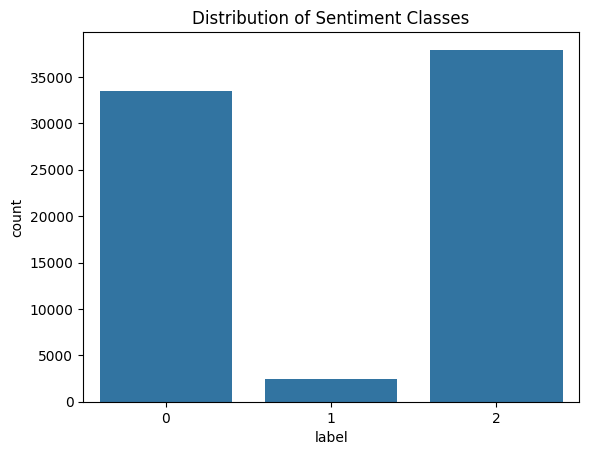

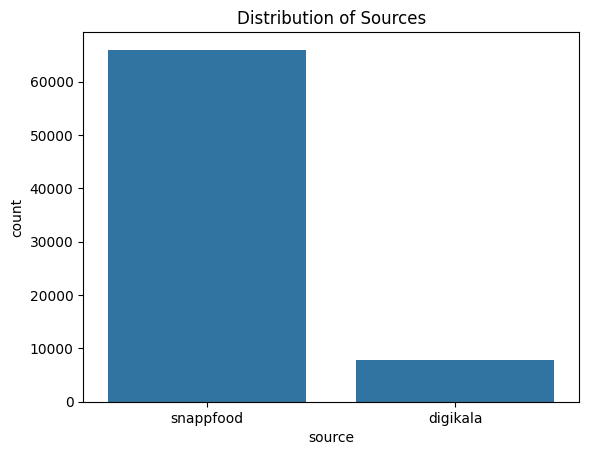

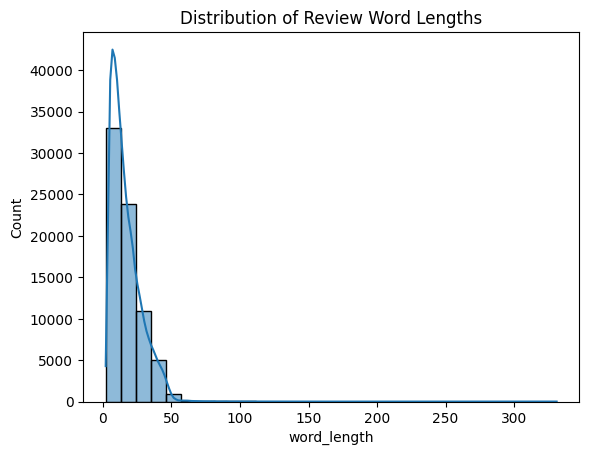

In [ ]:
df['char_length'] = df['text'].apply(len)
df['word_length'] = df['text'].apply(lambda x: len(x.split()))

sns.countplot(data=df, x='label')
plt.title('Distribution of Sentiment Classes')
plt.show()

sns.countplot(data=df, x='source')
plt.title('Distribution of Sources')
plt.show()

sns.histplot(df['word_length'], bins=30, kde=True)
plt.title('Distribution of Review Word Lengths')
plt.show()

In [ ]:
all_words = ' '.join(df['text'].dropna()).split()

word_counts = Counter(all_words)

print("Top 20 Raw Words:")
print(word_counts.most_common(20))

Top 20 Raw Words:
[('و', 49395), ('بود', 44870), ('به', 22690), ('از', 20266), ('که', 19843), ('خیلی', 19205), ('هم', 15834), ('با', 13549), ('کیفیت', 13106), ('غذا', 13071), ('خوب', 12740), ('عالی', 11667), ('در', 11136), ('این', 11115), ('می', 11018), ('بود.', 11000), ('شده', 9621), ('ولی', 9397), ('سفارش', 8963), ('بسیار', 8533)]


/tmp/ipykernel_659/587008425.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts, y=fixed_words, palette="magma")


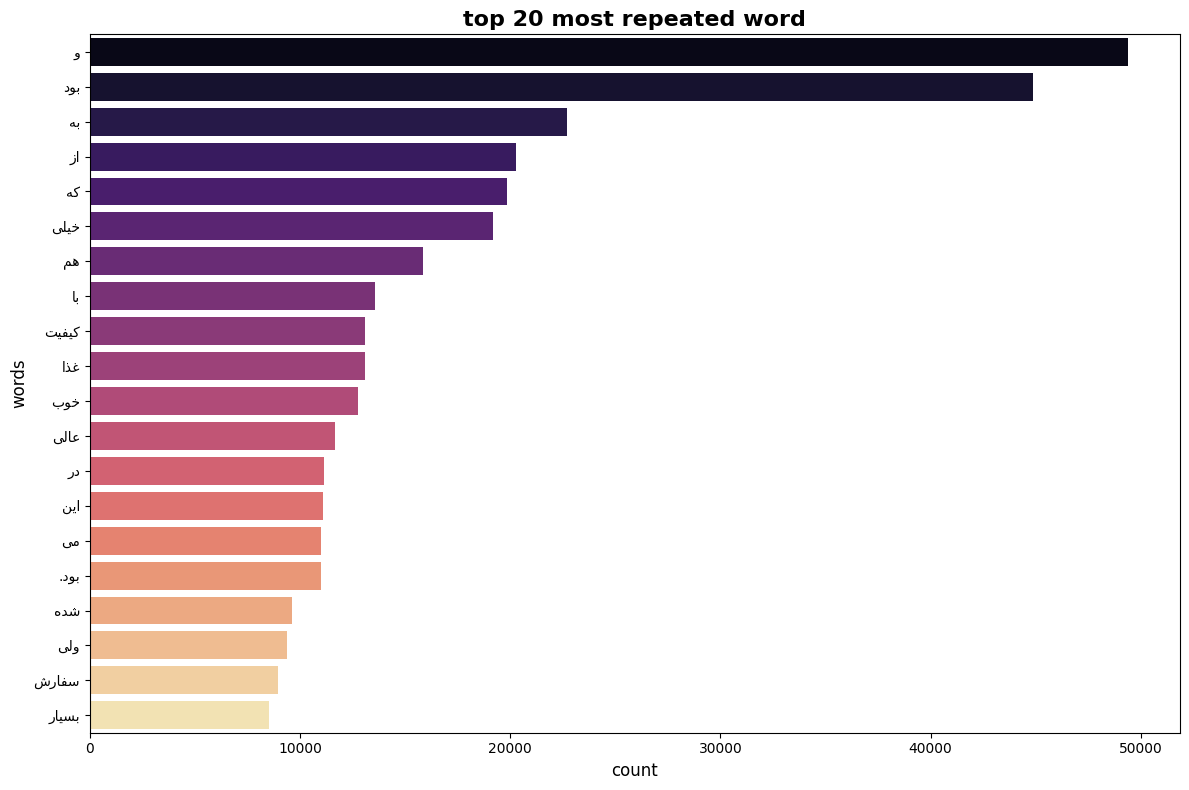

In [ ]:
top_20 = word_counts.most_common(20)
raw_words = [item[0] for item in top_20]
counts = [item[1] for item in top_20]

fixed_words = [get_display(reshape(word)) for word in raw_words]

plt.figure(figsize=(12, 8))
sns.barplot(x=counts, y=fixed_words, palette="magma")

plt.title(get_display(reshape("top 20 most repeated word")), fontsize=16, fontweight='bold')
plt.xlabel(get_display(reshape("count")), fontsize=12)
plt.ylabel(get_display(reshape("words")), fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
from hazm import stopwords_list

hazm_stop_words = set(stopwords_list())

def remove_stopwords(text):
    return ' '.join([word for word in text.split() if word not in hazm_stop_words])

df['Cleaned Text - No Stopwords'] = df['text'].apply(remove_stopwords)

all_words_no_stopwords = ' '.join(df['Cleaned Text - No Stopwords'].dropna()).split()

word_counts_no_stopwords = Counter(all_words_no_stopwords)

print("Top 20 Words After Stop Word Removal:")
print(word_counts_no_stopwords.most_common(20))

Top 20 Words After Stop Word Removal:
[('کیفیت', 13106), ('غذا', 13071), ('بود.', 11000), ('سفارش', 8963), ('پیتزا', 6576), ('واقعا', 6084), ('سرد', 5962), ('اصلا', 5761), ('خوشمزه', 5379), ('ها', 5320), ('ارسال', 4733), ('طعم', 4366), ('ممنون', 4300), ('تازه', 4244), ('بد', 4170), ('مرغ', 4155), ('های', 4144), ('پیک', 3840), ('یه', 3813), ('مزه', 3789)]


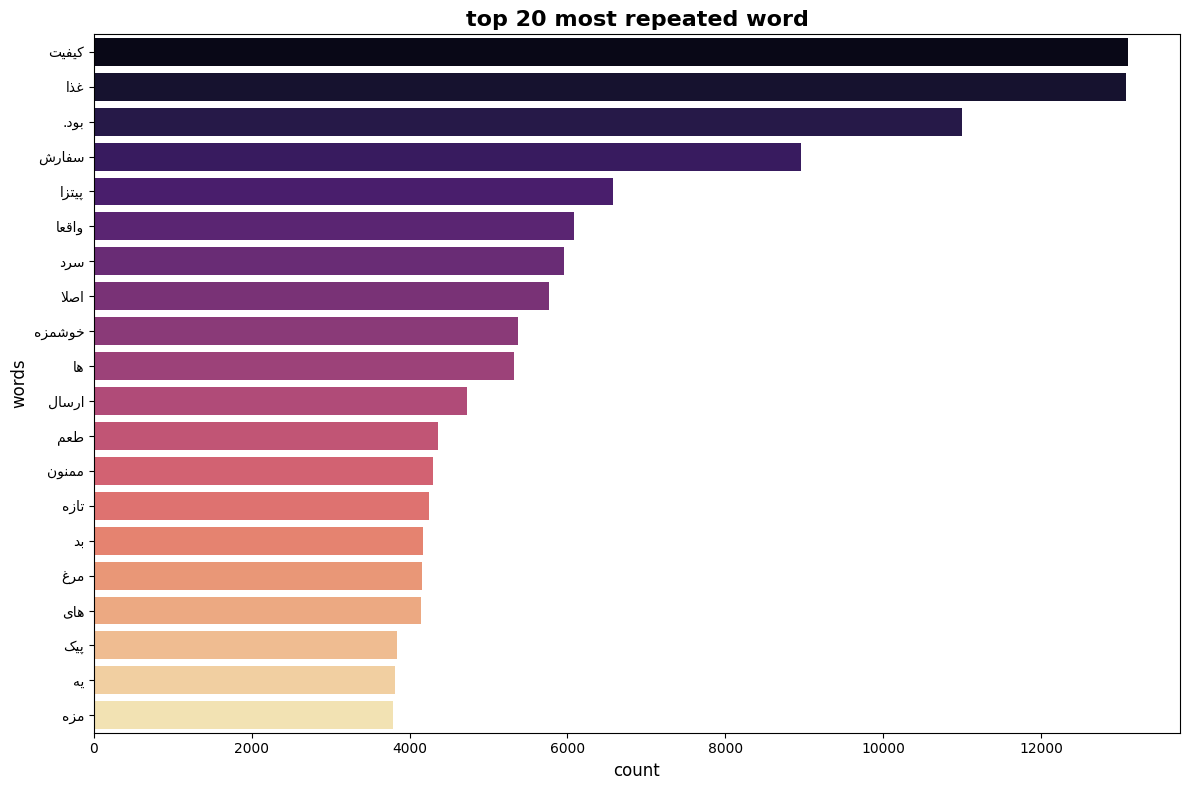

In [ ]:
top_20_no_stopwords = word_counts_no_stopwords.most_common(20)
raw_words_no_stopwords = [item[0] for item in top_20_no_stopwords]
counts_no_stopwords = [item[1] for item in top_20_no_stopwords]

fixed_words_no_stopwords = [get_display(reshape(word)) for word in raw_words_no_stopwords]

plt.figure(figsize=(12, 8))
sns.barplot(x=counts_no_stopwords, y=fixed_words_no_stopwords, palette="magma", hue=fixed_words_no_stopwords, legend=False)

plt.title(get_display(reshape("top 20 most repeated word")), fontsize=16, fontweight='bold')
plt.xlabel(get_display(reshape("count")), fontsize=12)
plt.ylabel(get_display(reshape("words")), fontsize=12)

plt.tight_layout()
plt.show()



# Data Pre-Processing:

In [ ]:
print(f"Total rows of the sample before droping nulls and duplicates: {len(df)}")
df = df.dropna(subset=['text', 'label'])
df = df.drop_duplicates(subset=['text'])
df = df.reset_index(drop=True)
print(f"Total rows of the sample after droping nulls and duplicates: {len(df)}")


normalizer = Normalizer()
informal_normalizer = InformalNormalizer()
tokenizer = WordTokenizer()

finglish_dict = {
    "khili": "خیلی", "kheyli": "خیلی", "khoob": "خوب", "khob": "خوب",
    "awli": "عالی", "ali": "عالی", "alii": "عالی", "eftezah": "افتضاح",
    "merci": "مرسی", "mamnoon": "ممنون", "tnx": "ممنون"
}


def preprocess_persian_text(text):
    if not isinstance(text, str):
        return ""

    text = normalizer.normalize(text)

    text = emoji.demojize(text, delimiters=(" _emoji_", "_ "))

    words = text.lower().split()
    translated_words = [finglish_dict[w] if w in finglish_dict else w for w in words]
    text = " ".join(translated_words)

    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    text = re.sub(r'[^a-zA-Z0-9_\s\u0600-\u06FF]', ' ', text)

    # Character Elongation Squashing
    text = re.sub(r'(.)\1{2,}', r'\1', text)

    # Whitespace and Tab Compacting
    text = re.sub(r'\s+', ' ', text).strip()

    sentence_words = text.split()
    final_words = []
    for word in sentence_words:
        if not word.startswith("_emoji_"):
            variants = informal_normalizer.normalize(word)
            if variants and isinstance(variants, list) and len(variants) > 0:
                word = str(variants[0][0])
        final_words.append(word)

    text = " ".join(final_words)

    return text

df['Cleaned Review'] = df['text'].apply(preprocess_persian_text)

df['Tokens'] = [tokenizer.tokenize(str(review)) for review in df['Cleaned Review']]

df_baseline_cleaned = df.copy()

Total rows of the sample before droping nulls and duplicates: 73828
Total rows of the sample after droping nulls and duplicates: 73828


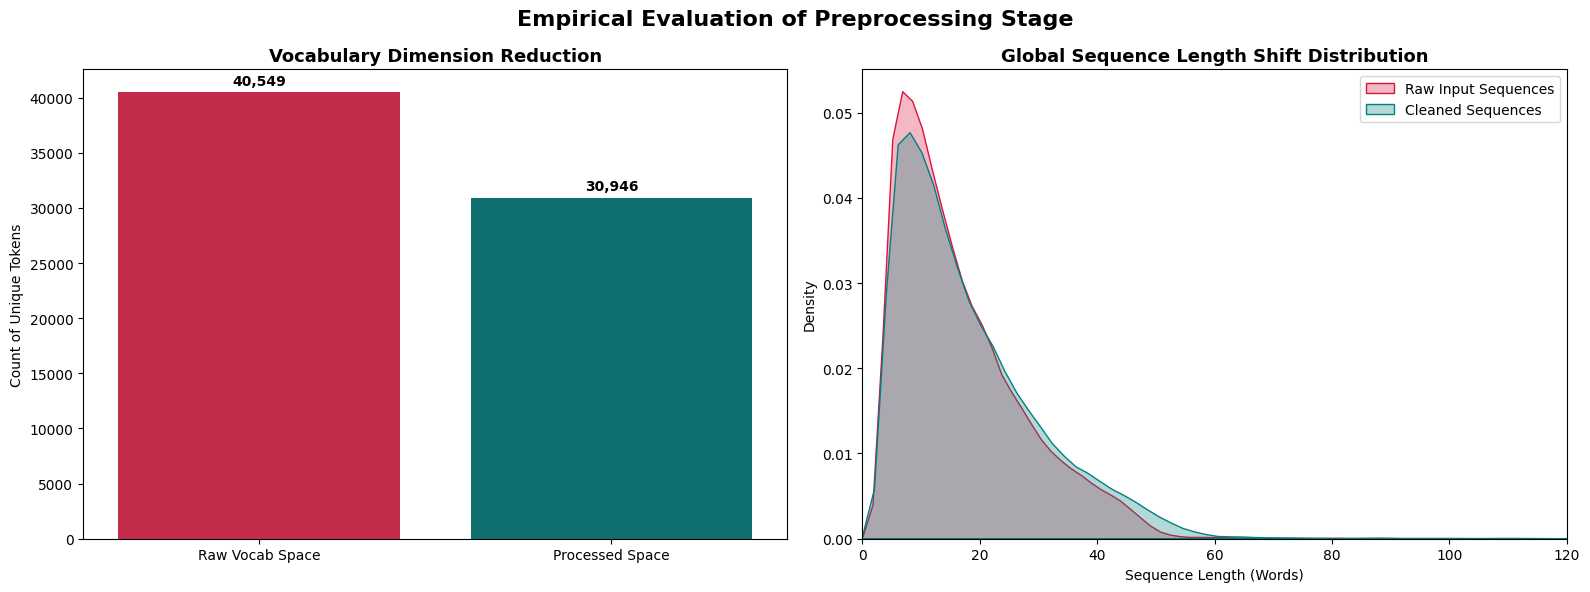


[METRICS] Total Unique Tokens Compressed from 40,549 to 30,946
[METRICS] Vocabulary Dimension Shrunk by: 23.68%


In [ ]:
df['word_count_raw'] = df['text'].astype(str).apply(lambda x: len(x.split()))
df['word_count_advanced'] = df['Cleaned Review'].astype(str).apply(lambda x: len(x.split()))

raw_unique_vocab = len(set(' '.join(df['text'].dropna().astype(str)).split()))
clean_unique_vocab = len(set(' '.join(df['Cleaned Review'].dropna().astype(str)).split()))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=['Raw Vocab Space', 'Processed Space'],
    y=[raw_unique_vocab, clean_unique_vocab],
    hue=['Raw Vocab Space', 'Processed Space'],
    palette=['crimson', 'teal'],
    ax=axes[0],
    legend=False
)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontweight='bold')
axes[0].set_title('Vocabulary Dimension Reduction', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count of Unique Tokens')

sns.kdeplot(df['word_count_raw'], color='crimson', label='Raw Input Sequences', fill=True, alpha=0.3, ax=axes[1])
sns.kdeplot(df['word_count_advanced'], color='teal', label='Cleaned Sequences', fill=True, alpha=0.3, ax=axes[1])
axes[1].set_xlim(0, 120)
axes[1].set_title('Global Sequence Length Shift Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Sequence Length (Words)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.suptitle('Empirical Evaluation of Preprocessing Stage', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

print(f"\n[METRICS] Total Unique Tokens Compressed from {raw_unique_vocab:,} to {clean_unique_vocab:,}")
print(f"[METRICS] Vocabulary Dimension Shrunk by: {((raw_unique_vocab - clean_unique_vocab) / raw_unique_vocab) * 100:.2f}%")

In [ ]:
def generate_preprocessing_report(df_raw, df_clean, raw_text_col='text', clean_text_col='Cleaned Review'):
    print("=" * 60)
    print("          DATA PREPROCESSING DIAGNOSTIC REPORT          ")
    print("=" * 60)

    initial_rows = len(df_raw)
    final_rows = len(df_clean)
    rows_removed = initial_rows - final_rows

    print(f"📊 DATASET DIMENSIONS:")
    print(f"   • Initial Row Count (Raw): {initial_rows:,}")
    print(f"   • Final Row Count (Clean):   {final_rows:,}")
    print(f"   • Rows Removed (Duplicates/Nulls): {rows_removed:,} ({ (rows_removed/initial_rows)*100:.2f}% reduction)")
    print("-" * 60)

    raw_vocab = set(' '.join(df_raw[raw_text_col].dropna().astype(str)).split())
    clean_vocab = set(' '.join(df_clean[clean_text_col].dropna().astype(str)).split())

    raw_vocab_size = len(raw_vocab)
    clean_vocab_size = len(clean_vocab)
    vocab_compression = ((raw_vocab_size - clean_vocab_size) / raw_vocab_size) * 100

    print(f"🔤 VOCABULARY COMPRESSION:")
    print(f"   • Unique Raw Tokens:    {raw_vocab_size:,}")
    print(f"   • Unique Cleaned Tokens: {clean_vocab_size:,}")
    print(f"   • Vocabulary Compressed By: {vocab_compression:.2f}% (Fewer unique words for model to learn)")
    print("-" * 60)

    raw_lengths = df_raw[raw_text_col].dropna().astype(str).apply(lambda x: len(x.split()))
    clean_lengths = df_clean[clean_text_col].dropna().astype(str).apply(lambda x: len(x.split()))

    print(f"📏 SEQUENCE LENGTH CHARACTERISTICS (WORD COUNTS):")
    print(f"   • Average Length:  Raw = {raw_lengths.mean():.2f} words | Clean = {clean_lengths.mean():.2f} words")
    print(f"   • Median Length:   Raw = {raw_lengths.median():.1f} words | Clean = {clean_lengths.median():.1f} words")
    print(f"   • Maximum Length:  Raw = {raw_lengths.max():,} words | Clean = {clean_lengths.max():,} words")
    print("-" * 60)

    elongated_raw_sample_count = df_raw[raw_text_col].dropna().astype(str).str.contains(r'(.)\1{2,}', regex=True).sum()
    elongated_clean_sample_count = df_clean[clean_text_col].dropna().astype(str).str.contains(r'(.)\1{2,}', regex=True).sum()

    print(f"🛠️ PIPELINE INTEGRITY AUDIT:")
    print(f"   • Samples with character stretching:  Before = {elongated_raw_sample_count:,} | After = {elongated_clean_sample_count:,}")

    english_char_raw = df_raw[raw_text_col].dropna().astype(str).str.contains(r'[a-zA-Z]', regex=True).sum()
    english_char_clean = df_clean[clean_text_col].dropna().astype(str).str.contains(r'[a-zA-Z](?!_emoji)', regex=True).sum()
    print(f"   • Samples containing English/Latin letters: Before = {english_char_raw:,} | After = {english_char_clean:,}")
    print("=" * 60)

generate_preprocessing_report(
    df_raw=df_raw,
    df_clean=df_baseline_cleaned,
    raw_text_col='text',
    clean_text_col='Cleaned Review'
)

          DATA PREPROCESSING DIAGNOSTIC REPORT          
📊 DATASET DIMENSIONS:
   • Initial Row Count (Raw): 73,828
   • Final Row Count (Clean):   73,828
   • Rows Removed (Duplicates/Nulls): 0 (0.00% reduction)
------------------------------------------------------------
🔤 VOCABULARY COMPRESSION:
   • Unique Raw Tokens:    40,549
   • Unique Cleaned Tokens: 30,946
   • Vocabulary Compressed By: 23.68% (Fewer unique words for model to learn)
------------------------------------------------------------
📏 SEQUENCE LENGTH CHARACTERISTICS (WORD COUNTS):
   • Average Length:  Raw = 16.80 words | Clean = 18.17 words
   • Median Length:   Raw = 14.0 words | Clean = 15.0 words
   • Maximum Length:  Raw = 331 words | Clean = 396 words
------------------------------------------------------------


/tmp/ipykernel_659/3787487647.py:38: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  elongated_raw_sample_count = df_raw[raw_text_col].dropna().astype(str).str.contains(r'(.)\1{2,}', regex=True).sum()
/tmp/ipykernel_659/3787487647.py:39: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  elongated_clean_sample_count = df_clean[clean_text_col].dropna().astype(str).str.contains(r'(.)\1{2,}', regex=True).sum()


🛠️ PIPELINE INTEGRITY AUDIT:
   • Samples with character stretching:  Before = 2,213 | After = 0
   • Samples containing English/Latin letters: Before = 3,261 | After = 14,581


# Text Representation:

In [ ]:
class Vocabulary:
    def __init__(self, min_repetition=2):
        self.min_repetition = min_repetition
        self.string_to_integer = {"<PAD>": 0, "<UNK>": 1}
        self.integer_to_trings = {0: "<PAD>", 1: "<UNK>"}

    def build_vocabulary(self, tokenized_series):
        repetition = Counter()
        for tokens in tokenized_series:
            repetition.update(tokens)

        i = 2
        for word, count in repetition.items():
            if count >= self.min_repetition:
                self.string_to_integer[word] = i
                self.integer_to_trings[i] = word
                i += 1

    def numericalize(self, tokens):
        return [self.string_to_integer.get(token, self.string_to_integer["<UNK>"]) for token in tokens]

vocab = Vocabulary(min_repetition=2)
vocab.build_vocabulary(df['Tokens'])
vocab_size = len(vocab.string_to_integer)

df['Numeric_Sequences'] = df['Tokens'].apply(vocab.numericalize)


sequence_lengths = df['Tokens'].apply(len)
max_length = int(np.percentile(sequence_lengths, 95))


def pad_sequence(seq, max_length):
    if len(seq) >= max_length:
        return seq[:max_length]
    else:
        return [0] * (max_length - len(seq)) + seq

padded_sequences = np.array([pad_sequence(seq, max_length) for seq in df['Numeric_Sequences']])
labels = df['label'].values



df['stratify_key'] = df['label'].astype(str) + "_" + df['source'].astype(str)

X_train, X_temp, y_train, y_temp, _, strat_temp = train_test_split(padded_sequences, labels, df['stratify_key'],
    test_size=0.3, random_state=42, stratify=df['stratify_key'])

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5, random_state=42, stratify=strat_temp
)


train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(y_train, dtype=torch.long))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.long), torch.tensor(y_val, dtype=torch.long))
test_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.long), torch.tensor(y_test, dtype=torch.long))

# Three architectures:

In [ ]:
class RNNClass(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, dropout_rate, output_dim=3):
        super(RNNClass, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        rnn_dropout = dropout_rate if num_layers > 1 else 0.0

        self.rnn = nn.RNN(
            input_size = embedding_dim,
            hidden_size = hidden_dim,
            num_layers = num_layers,
            batch_first = True,
            dropout = rnn_dropout
        )

        self.dropout = nn.Dropout(dropout_rate)

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text_batch):

        embedded = self.dropout(self.embedding(text_batch))

        output, hidden = self.rnn(embedded)

        final_hidden = hidden[-1, :, :]

        return self.fc(self.dropout(final_hidden))

In [ ]:
class GRUClass(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, dropout_rate, output_dim=3):

        super(GRUClass, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        gru_dropout = dropout_rate if num_layers > 1 else 0.0

        self.gru = nn.GRU(
            input_size = embedding_dim,
            hidden_size = hidden_dim,
            num_layers = num_layers,
            batch_first = True,
            dropout = gru_dropout
        )

        self.dropout = nn.Dropout(dropout_rate)

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text_batch):

        embedded = self.dropout(self.embedding(text_batch))

        output, hidden = self.gru(embedded)

        final_hidden = hidden[-1, :, :]

        return self.fc(self.dropout(final_hidden))

In [ ]:
class LSTMClass(nn.Module):

    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, dropout_rate, output_dim=3):

        super(LSTMClass, self).__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)

        lstm_dropout = dropout_rate if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size = embedding_dim,
            hidden_size = hidden_dim,
            num_layers = num_layers,
            batch_first = True,
            dropout = lstm_dropout
        )

        self.dropout = nn.Dropout(dropout_rate)

        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, text_batch):

        embedded = self.dropout(self.embedding(text_batch))

        output, (hidden, cell) = self.lstm(embedded)

        final_hidden = hidden[-1, :, :]

        return self.fc(self.dropout(final_hidden))

# Finding the best hyper-parameter set:

In [ ]:
computed_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class_weights = torch.tensor(computed_weights, dtype=torch.float).to(device)

print("class weights:")
for idx, weight in enumerate(computed_weights):
    print(f" Class {idx} Weight Multiplier: {weight:.4f}")

class weights:
 Class 0 Weight Multiplier: 0.7351
 Class 1 Weight Multiplier: 10.2173
 Class 2 Weight Multiplier: 0.6486


In [ ]:
random.seed(42)

ARCHITECTURES_TO_TEST = [RNNClass, GRUClass, LSTMClass]

search_space = {
    "num_layers": [1, 2, 3],
    "hidden_dim": [64, 128, 256],
    "dropout_rate": [0.2, 0.3, 0.5],
    "learning_rate": [1e-3, 5e-4, 1e-4],
    "batch_size": [32, 64, 128]
}

EMBEDDING_DIM = 128

OUTPUT_DIM = 3

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

train_criterion = nn.CrossEntropyLoss(weight=class_weights)

val_criterion = nn.CrossEntropyLoss()

NUM_EXPERIMENTS_PER_ARCH = 5

global_best_profiles = {}

for model_class in ARCHITECTURES_TO_TEST:

    arch_name = model_class.__name__

    print(f"\n Starting FOR ARCHITECTURE: {arch_name} \n")

    best_val_loss = float('inf')

    best_hyperparameters = None

    for experiment_idx in range(NUM_EXPERIMENTS_PER_ARCH):

        config = {param: random.choice(values) for param, values in search_space.items()}

        print(f"\n[{arch_name}] Experiment {experiment_idx + 1}/{NUM_EXPERIMENTS_PER_ARCH}")

        print(f"Parameters: {config}")

        np.random.seed(42)
        torch.manual_seed(42)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(42)

        train_loader = DataLoader(train_dataset, batch_size=config['batch_size'], shuffle=True)

        val_loader = DataLoader(val_dataset, batch_size=config['batch_size'], shuffle=False)

        model = model_class(
            vocab_size = vocab_size,
            embedding_dim = EMBEDDING_DIM,
            hidden_dim = config['hidden_dim'],
            num_layers = config['num_layers'],
            dropout_rate = config['dropout_rate'],
            output_dim = OUTPUT_DIM
        ).to(device)

        optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])

        model.train()

        for epoch in range(2):

            for texts, targets in train_loader:

                texts, targets = texts.to(device), targets.to(device)

                optimizer.zero_grad()

                predictions = model(texts)

                loss = train_criterion(predictions, targets)

                loss.backward()

                optimizer.step()

        model.eval()

        total_val_loss = 0.0

        with torch.no_grad():

            for texts, targets in val_loader:

                texts, targets = texts.to(device), targets.to(device)

                predictions = model(texts)

                loss = val_criterion(predictions, targets)

                total_val_loss += loss.item() * texts.size(0)

        average_val_loss = total_val_loss / len(val_loader.dataset)

        print(f"\n Clean Validation Loss Result: {average_val_loss:.4f}")

        if average_val_loss < best_val_loss:

            best_val_loss = average_val_loss

            best_hyperparameters = config

    global_best_profiles[arch_name] = {

        "best_config": best_hyperparameters,

        "best_loss": best_val_loss
    }

for arch_name, results in global_best_profiles.items():

    print(f"\nArchitecture Profile: {arch_name}")
    print(f"  Best Achieved Clean Loss: {results['best_loss']:.4f}")
    print(f" Optimal Configurations: {results['best_config']}")


 Starting FOR ARCHITECTURE: RNNClass 


[RNNClass] Experiment 1/5
Parameters: {'num_layers': 3, 'hidden_dim': 64, 'dropout_rate': 0.2, 'learning_rate': 0.0001, 'batch_size': 64}

 Clean Validation Loss Result: 0.8555

[RNNClass] Experiment 2/5
Parameters: {'num_layers': 1, 'hidden_dim': 64, 'dropout_rate': 0.2, 'learning_rate': 0.0001, 'batch_size': 32}

 Clean Validation Loss Result: 0.8955

[RNNClass] Experiment 3/5
Parameters: {'num_layers': 3, 'hidden_dim': 256, 'dropout_rate': 0.5, 'learning_rate': 0.001, 'batch_size': 128}

 Clean Validation Loss Result: 0.9781

[RNNClass] Experiment 4/5
Parameters: {'num_layers': 2, 'hidden_dim': 64, 'dropout_rate': 0.2, 'learning_rate': 0.001, 'batch_size': 32}

 Clean Validation Loss Result: 0.8652

[RNNClass] Experiment 5/5
Parameters: {'num_layers': 1, 'hidden_dim': 256, 'dropout_rate': 0.5, 'learning_rate': 0.001, 'batch_size': 128}

 Clean Validation Loss Result: 0.9533

 Starting FOR ARCHITECTURE: GRUClass 


[GRUClass] Experiment 1/5
Pa

In [ ]:
def generate_architecture_diagram(model_name, b_size, seq_len, emb_dim, hid_dim, num_lay):

    dot = Digraph(comment='Neural Pipeline Structural Schematic', format='png')
    dot.attr(rankdir='TB', size='8,10', dpi='300')
    dot.attr('node', shape='box', style='filled,rounded', fontname='Helvetica',
             color='#2C3E50', fillcolor='#ECF0F1', penwidth='2')
    dot.attr('edge', fontname='Helvetica', color='#34495E', penwidth='1.5')

    dot.node('A', f'Input Layer (Padded Token Indices)\nShape: [{b_size}, {seq_len}]', fillcolor='#AED6F1')
    dot.node('B', f'Trainable Embedding Lookup Layer\nShape: [{b_size}, {seq_len}, {emb_dim}]', fillcolor='#A9DFBF')
    dot.node('C', f'{model_name} Engine Block\nLayers: {num_lay} | Hidden Units: {hid_dim}', fillcolor='#F9E79F')
    dot.node('D', f'Slicing Structural Vector (hidden[-1, :, :])\nShape: [{b_size}, {hid_dim}]', fillcolor='#EDBB99')
    dot.node('E', f'Fully Connected Linear Layer Head\nShape: [{b_size}, 3]', fillcolor='#D2B4DE')
    dot.node('F', 'Output Class Classification Logits\nDimensions: [Negative, Neutral, Positive]', fillcolor='#F2D7D5')

    dot.edge('A', 'B', label=' Codebook Translation')
    dot.edge('B', 'C', label=' Dense 3D Tensors')
    dot.edge('C', 'D', label=' Sequence Summary Extraction')
    dot.edge('D', 'E', label=' Linear Classification Feature Warp')
    dot.edge('E', 'F', label=' CrossEntropy Cross-Check')

    output_filename = f"{model_name.lower()}_best_architecture"
    dot.render(output_filename, cleanup=True)
    print(f" Saved optimized schematic layout directly to: ./{output_filename}.png")


for arch_name, results in global_best_profiles.items():
    cfg = results['best_config']
    if cfg is None:
        continue

    generate_architecture_diagram(
        model_name=arch_name.replace("Classifier", ""),
        b_size = cfg['batch_size'],
        seq_len = max_length,
        emb_dim = EMBEDDING_DIM,
        hid_dim = cfg['hidden_dim'],
        num_lay = cfg['num_layers']
    )

 Saved optimized schematic layout directly to: ./rnnclass_best_architecture.png
 Saved optimized schematic layout directly to: ./gruclass_best_architecture.png
 Saved optimized schematic layout directly to: ./lstmclass_best_architecture.png


# Training


Training for RNN:

In [ ]:
all_model_history = {}

Epoch 01 | Train Loss: 1.0204 Macro F1: 0.3561 | Val Loss: 0.9904 Macro F1: 0.3852
  New optimal weights saved based on Macro F1 improvement!
Epoch 02 | Train Loss: 0.9269 Macro F1: 0.4067 | Val Loss: 0.8810 Macro F1: 0.4683
  New optimal weights saved based on Macro F1 improvement!
Epoch 03 | Train Loss: 0.8516 Macro F1: 0.4516 | Val Loss: 0.8610 Macro F1: 0.4988
  New optimal weights saved based on Macro F1 improvement!
Epoch 04 | Train Loss: 0.8197 Macro F1: 0.4756 | Val Loss: 0.9154 Macro F1: 0.4678
Epoch 05 | Train Loss: 0.7834 Macro F1: 0.4865 | Val Loss: 0.7622 Macro F1: 0.5559
  New optimal weights saved based on Macro F1 improvement!
Epoch 06 | Train Loss: 0.7918 Macro F1: 0.4898 | Val Loss: 0.7913 Macro F1: 0.5384
Epoch 07 | Train Loss: 0.7381 Macro F1: 0.5130 | Val Loss: 0.8361 Macro F1: 0.5277
Epoch 08 | Train Loss: 0.7923 Macro F1: 0.4817 | Val Loss: 0.7371 Macro F1: 0.5615
  New optimal weights saved based on Macro F1 improvement!
Epoch 09 | Train Loss: 0.7663 Macro F1: 0

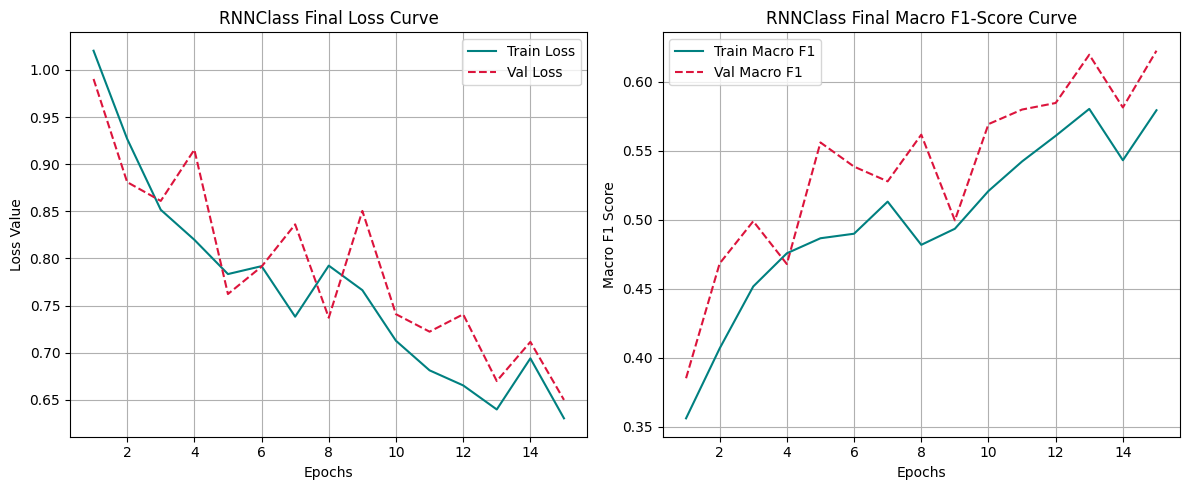

In [ ]:
SELECTED_ARCH = "RNNClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

DROPOUT_RATE  = best_config["dropout_rate"]

LEARNING_RATE = best_config["learning_rate"]

BATCH_SIZE    = best_config["batch_size"]

OUTPUT_DIM    = 3

EPOCHS        = 15

DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)

train_criterion = nn.CrossEntropyLoss(weight=class_weights)

val_criterion   = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses, val_losses = [], []

train_f1s, val_f1s = [], []

best_val_f1 = 0.0

for epoch in range(EPOCHS):

    model.train()

    total_train_loss, total_train = 0, 0

    train_preds, train_targets = [], []

    for batch_x, batch_y in train_loader:

        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = train_criterion(predictions, batch_y)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * batch_x.size(0)

        _, predicted = torch.max(predictions, 1)

        total_train += batch_y.size(0)

        train_preds.extend(predicted.cpu().numpy())

        train_targets.extend(batch_y.cpu().numpy())

    epoch_train_loss = total_train_loss / total_train

    epoch_train_f1 = f1_score(train_targets, train_preds, average='macro')

    model.eval()

    total_val_loss, total_val = 0, 0

    val_preds, val_targets = [], []

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

            predictions = model(batch_x)

            loss = val_criterion(predictions, batch_y)

            total_val_loss += loss.item() * batch_x.size(0)

            _, predicted = torch.max(predictions, 1)

            total_val += batch_y.size(0)

            val_preds.extend(predicted.cpu().numpy())

            val_targets.extend(batch_y.cpu().numpy())

    epoch_val_loss = total_val_loss / total_val

    epoch_val_f1 = f1_score(val_targets, val_preds, average='macro')

    train_losses.append(epoch_train_loss)

    val_losses.append(epoch_val_loss)

    train_f1s.append(epoch_train_f1)

    val_f1s.append(epoch_val_f1)

    print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} Macro F1: {epoch_train_f1:.4f} | Val Loss: {epoch_val_loss:.4f} Macro F1: {epoch_val_f1:.4f}")


    if epoch_val_f1 > best_val_f1:

        best_val_f1 = epoch_val_f1

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': best_val_f1,
            'config': best_config
        }, f"best_{SELECTED_ARCH}_production_model.pt")
        print(f"  New optimal weights saved based on Macro F1 improvement!")

#---------------------------------------------------------------

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', color='teal')
plt.plot(epochs_range, val_losses, label='Val Loss', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend()
plt.grid(True)

# Macro F1 Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_f1s, label='Train Macro F1', color='teal')
plt.plot(epochs_range, val_f1s, label='Val Macro F1', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Macro F1-Score Curve')
plt.xlabel('Epochs')
plt.ylabel('Macro F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

all_model_history["RNNClass"] = {
    "train_losses": train_losses.copy(), "val_losses": val_losses.copy(),
    "train_f1s": train_f1s.copy(), "val_f1s": val_f1s.copy()
}

Training for GRU:

Epoch 01 | Train Loss: 0.7315 Macro F1: 0.5270 | Val Loss: 0.5786 Macro F1: 0.6594
  New optimal weights saved based on Macro F1 improvement!
Epoch 02 | Train Loss: 0.4773 Macro F1: 0.6728 | Val Loss: 0.4755 Macro F1: 0.7168
  New optimal weights saved based on Macro F1 improvement!
Epoch 03 | Train Loss: 0.4214 Macro F1: 0.7057 | Val Loss: 0.4652 Macro F1: 0.7225
  New optimal weights saved based on Macro F1 improvement!
Epoch 04 | Train Loss: 0.3874 Macro F1: 0.7247 | Val Loss: 0.4671 Macro F1: 0.7166
Epoch 05 | Train Loss: 0.3570 Macro F1: 0.7454 | Val Loss: 0.4558 Macro F1: 0.7299
  New optimal weights saved based on Macro F1 improvement!
Epoch 06 | Train Loss: 0.3430 Macro F1: 0.7573 | Val Loss: 0.4550 Macro F1: 0.7353
  New optimal weights saved based on Macro F1 improvement!
Epoch 07 | Train Loss: 0.3251 Macro F1: 0.7716 | Val Loss: 0.4468 Macro F1: 0.7431
  New optimal weights saved based on Macro F1 improvement!
Epoch 08 | Train Loss: 0.3070 Macro F1: 0.7886 | Val Loss: 0.4137

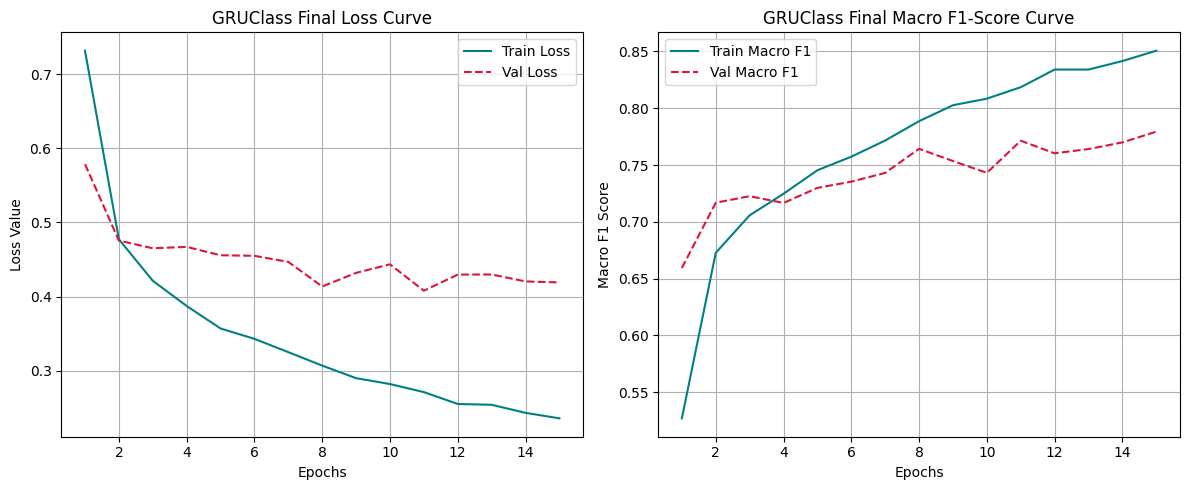

In [ ]:
SELECTED_ARCH = "GRUClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

DROPOUT_RATE  = best_config["dropout_rate"]

LEARNING_RATE = best_config["learning_rate"]

BATCH_SIZE    = best_config["batch_size"]

OUTPUT_DIM    = 3

EPOCHS        = 15

DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)

train_criterion = nn.CrossEntropyLoss(weight=class_weights)

val_criterion   = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses, val_losses = [], []

train_f1s, val_f1s = [], []

best_val_f1 = 0.0

for epoch in range(EPOCHS):

    model.train()

    total_train_loss, total_train = 0, 0

    train_preds, train_targets = [], []

    for batch_x, batch_y in train_loader:

        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = train_criterion(predictions, batch_y)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * batch_x.size(0)

        _, predicted = torch.max(predictions, 1)

        total_train += batch_y.size(0)

        train_preds.extend(predicted.cpu().numpy())

        train_targets.extend(batch_y.cpu().numpy())

    epoch_train_loss = total_train_loss / total_train

    epoch_train_f1 = f1_score(train_targets, train_preds, average='macro')

    model.eval()

    total_val_loss, total_val = 0, 0

    val_preds, val_targets = [], []

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

            predictions = model(batch_x)

            loss = val_criterion(predictions, batch_y)

            total_val_loss += loss.item() * batch_x.size(0)

            _, predicted = torch.max(predictions, 1)

            total_val += batch_y.size(0)

            val_preds.extend(predicted.cpu().numpy())

            val_targets.extend(batch_y.cpu().numpy())

    epoch_val_loss = total_val_loss / total_val

    epoch_val_f1 = f1_score(val_targets, val_preds, average='macro')

    train_losses.append(epoch_train_loss)

    val_losses.append(epoch_val_loss)

    train_f1s.append(epoch_train_f1)

    val_f1s.append(epoch_val_f1)

    print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} Macro F1: {epoch_train_f1:.4f} | Val Loss: {epoch_val_loss:.4f} Macro F1: {epoch_val_f1:.4f}")


    if epoch_val_f1 > best_val_f1:

        best_val_f1 = epoch_val_f1

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': best_val_f1,
            'config': best_config
        }, f"best_{SELECTED_ARCH}_production_model.pt")
        print(f"  New optimal weights saved based on Macro F1 improvement!")

#---------------------------------------------------------------

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', color='teal')
plt.plot(epochs_range, val_losses, label='Val Loss', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend()
plt.grid(True)

# Macro F1 Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_f1s, label='Train Macro F1', color='teal')
plt.plot(epochs_range, val_f1s, label='Val Macro F1', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Macro F1-Score Curve')
plt.xlabel('Epochs')
plt.ylabel('Macro F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

all_model_history["GRUClass"] = {
    "train_losses": train_losses.copy(), "val_losses": val_losses.copy(),
    "train_f1s": train_f1s.copy(), "val_f1s": val_f1s.copy()
}

Training for LSTM:

Epoch 01 | Train Loss: 0.6430 Macro F1: 0.5886 | Val Loss: 0.5375 Macro F1: 0.6683
  New optimal weights saved based on Macro F1 improvement!
Epoch 02 | Train Loss: 0.4383 Macro F1: 0.7042 | Val Loss: 0.5126 Macro F1: 0.6904
  New optimal weights saved based on Macro F1 improvement!
Epoch 03 | Train Loss: 0.3841 Macro F1: 0.7347 | Val Loss: 0.4169 Macro F1: 0.7480
  New optimal weights saved based on Macro F1 improvement!
Epoch 04 | Train Loss: 0.3491 Macro F1: 0.7624 | Val Loss: 0.4094 Macro F1: 0.7560
  New optimal weights saved based on Macro F1 improvement!
Epoch 05 | Train Loss: 0.3194 Macro F1: 0.7884 | Val Loss: 0.4343 Macro F1: 0.7342
Epoch 06 | Train Loss: 0.3009 Macro F1: 0.8005 | Val Loss: 0.4172 Macro F1: 0.7574
  New optimal weights saved based on Macro F1 improvement!
Epoch 07 | Train Loss: 0.2862 Macro F1: 0.8141 | Val Loss: 0.4294 Macro F1: 0.7637
  New optimal weights saved based on Macro F1 improvement!
Epoch 08 | Train Loss: 0.2642 Macro F1: 0.8326 | Val Loss: 0.4244

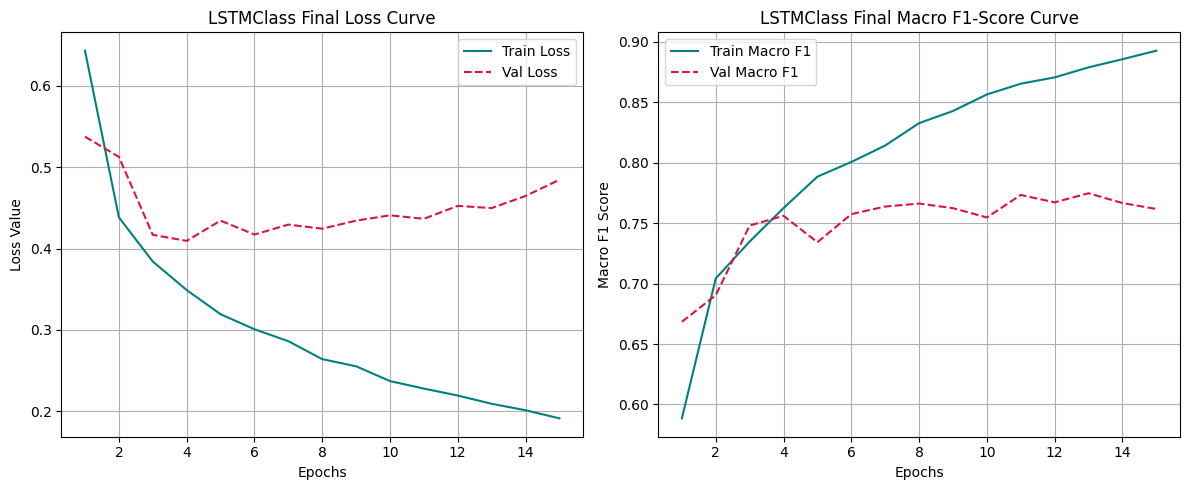

In [ ]:
SELECTED_ARCH = "LSTMClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

DROPOUT_RATE  = best_config["dropout_rate"]

LEARNING_RATE = best_config["learning_rate"]

BATCH_SIZE    = best_config["batch_size"]

OUTPUT_DIM    = 3

EPOCHS        = 15

DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)

train_criterion = nn.CrossEntropyLoss(weight=class_weights)

val_criterion   = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

train_losses, val_losses = [], []

train_f1s, val_f1s = [], []

best_val_f1 = 0.0

for epoch in range(EPOCHS):

    model.train()

    total_train_loss, total_train = 0, 0

    train_preds, train_targets = [], []

    for batch_x, batch_y in train_loader:

        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = train_criterion(predictions, batch_y)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * batch_x.size(0)

        _, predicted = torch.max(predictions, 1)

        total_train += batch_y.size(0)

        train_preds.extend(predicted.cpu().numpy())

        train_targets.extend(batch_y.cpu().numpy())

    epoch_train_loss = total_train_loss / total_train

    epoch_train_f1 = f1_score(train_targets, train_preds, average='macro')

    model.eval()

    total_val_loss, total_val = 0, 0

    val_preds, val_targets = [], []

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

            predictions = model(batch_x)

            loss = val_criterion(predictions, batch_y)

            total_val_loss += loss.item() * batch_x.size(0)

            _, predicted = torch.max(predictions, 1)

            total_val += batch_y.size(0)

            val_preds.extend(predicted.cpu().numpy())

            val_targets.extend(batch_y.cpu().numpy())

    epoch_val_loss = total_val_loss / total_val

    epoch_val_f1 = f1_score(val_targets, val_preds, average='macro')

    train_losses.append(epoch_train_loss)

    val_losses.append(epoch_val_loss)

    train_f1s.append(epoch_train_f1)

    val_f1s.append(epoch_val_f1)

    print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} Macro F1: {epoch_train_f1:.4f} | Val Loss: {epoch_val_loss:.4f} Macro F1: {epoch_val_f1:.4f}")


    if epoch_val_f1 > best_val_f1:

        best_val_f1 = epoch_val_f1

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': best_val_f1,
            'config': best_config
        }, f"best_{SELECTED_ARCH}_production_model.pt")
        print(f"  New optimal weights saved based on Macro F1 improvement!")

#---------------------------------------------------------------

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', color='teal')
plt.plot(epochs_range, val_losses, label='Val Loss', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend()
plt.grid(True)

# Macro F1 Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_f1s, label='Train Macro F1', color='teal')
plt.plot(epochs_range, val_f1s, label='Val Macro F1', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Macro F1-Score Curve')
plt.xlabel('Epochs')
plt.ylabel('Macro F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Second training on LSTM - preventing overfitting:

Epoch 01 | Train Loss: 0.7051 Macro F1: 0.5632 | Val Loss: 0.5459 Macro F1: 0.6697
  New optimal weights saved based on Macro F1 improvement!
Epoch 02 | Train Loss: 0.4656 Macro F1: 0.6865 | Val Loss: 0.4739 Macro F1: 0.7096
  New optimal weights saved based on Macro F1 improvement!
Epoch 03 | Train Loss: 0.4156 Macro F1: 0.7172 | Val Loss: 0.4478 Macro F1: 0.7273
  New optimal weights saved based on Macro F1 improvement!
Epoch 04 | Train Loss: 0.3846 Macro F1: 0.7397 | Val Loss: 0.4248 Macro F1: 0.7395
  New optimal weights saved based on Macro F1 improvement!
Epoch 05 | Train Loss: 0.3673 Macro F1: 0.7474 | Val Loss: 0.4006 Macro F1: 0.7626
  New optimal weights saved based on Macro F1 improvement!
Epoch 06 | Train Loss: 0.3544 Macro F1: 0.7579 | Val Loss: 0.3958 Macro F1: 0.7658
  New optimal weights saved based on Macro F1 improvement!
Epoch 07 | Train Loss: 0.3378 Macro F1: 0.7703 | Val Loss: 0.4626 Macro F1: 0.7295
Epoch 08 | Train Loss: 0.3297 Macro F1: 0.7792 | Val Loss: 0.4487

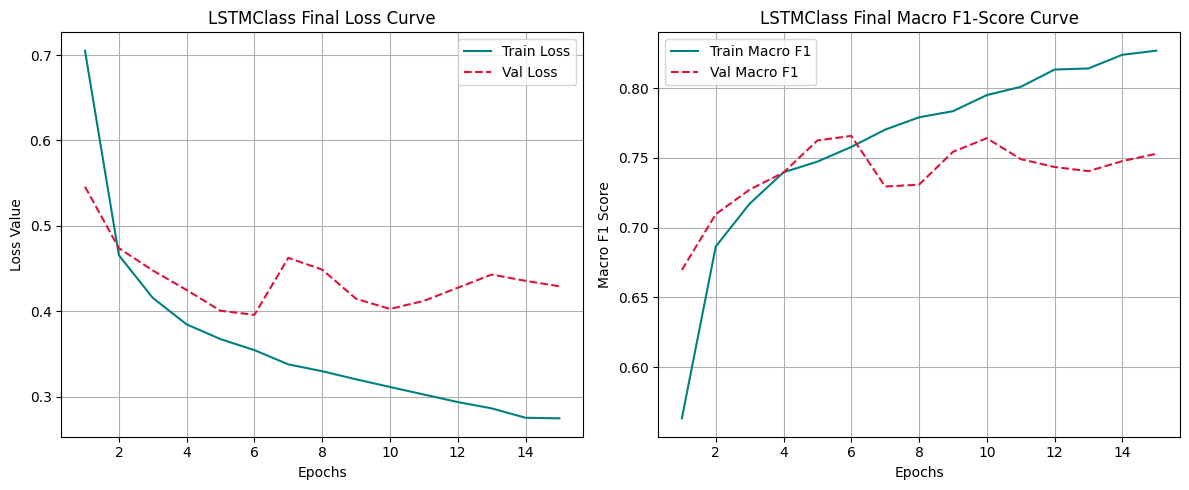

In [ ]:
SELECTED_ARCH = "LSTMClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

#Increases the dropout rate
DROPOUT_RATE  = min(best_config["dropout_rate"] + 0.15, 0.50)

LEARNING_RATE = best_config["learning_rate"]

BATCH_SIZE    = best_config["batch_size"]

OUTPUT_DIM    = 3

EPOCHS        = 15

DEVICE        = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)

train_criterion = nn.CrossEntropyLoss(weight=class_weights)

val_criterion   = nn.CrossEntropyLoss()

# Adding L2 regularization
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

train_losses, val_losses = [], []

train_f1s, val_f1s = [], []

best_val_f1 = 0.0

for epoch in range(EPOCHS):

    model.train()

    total_train_loss, total_train = 0, 0

    train_preds, train_targets = [], []

    for batch_x, batch_y in train_loader:

        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        optimizer.zero_grad()

        predictions = model(batch_x)

        loss = train_criterion(predictions, batch_y)

        loss.backward()

        optimizer.step()

        total_train_loss += loss.item() * batch_x.size(0)

        _, predicted = torch.max(predictions, 1)

        total_train += batch_y.size(0)

        train_preds.extend(predicted.cpu().numpy())

        train_targets.extend(batch_y.cpu().numpy())

    epoch_train_loss = total_train_loss / total_train

    epoch_train_f1 = f1_score(train_targets, train_preds, average='macro')

    model.eval()

    total_val_loss, total_val = 0, 0

    val_preds, val_targets = [], []

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

            predictions = model(batch_x)

            loss = val_criterion(predictions, batch_y)

            total_val_loss += loss.item() * batch_x.size(0)

            _, predicted = torch.max(predictions, 1)

            total_val += batch_y.size(0)

            val_preds.extend(predicted.cpu().numpy())

            val_targets.extend(batch_y.cpu().numpy())

    epoch_val_loss = total_val_loss / total_val

    epoch_val_f1 = f1_score(val_targets, val_preds, average='macro')

    train_losses.append(epoch_train_loss)

    val_losses.append(epoch_val_loss)

    train_f1s.append(epoch_train_f1)

    val_f1s.append(epoch_val_f1)

    print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} Macro F1: {epoch_train_f1:.4f} | Val Loss: {epoch_val_loss:.4f} Macro F1: {epoch_val_f1:.4f}")


    if epoch_val_f1 > best_val_f1:

        best_val_f1 = epoch_val_f1

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': best_val_f1,
            'config': best_config
        }, f"best_{SELECTED_ARCH}_production_model.pt")
        print(f"  New optimal weights saved based on Macro F1 improvement!")

#---------------------------------------------------------------

epochs_range = range(1, EPOCHS + 1)
plt.figure(figsize=(12, 5))

# Loss Plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label='Train Loss', color='teal')
plt.plot(epochs_range, val_losses, label='Val Loss', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend()
plt.grid(True)

# Macro F1 Plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_f1s, label='Train Macro F1', color='teal')
plt.plot(epochs_range, val_f1s, label='Val Macro F1', linestyle='--', color='crimson')
plt.title(f'{SELECTED_ARCH} Final Macro F1-Score Curve')
plt.xlabel('Epochs')
plt.ylabel('Macro F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

all_model_history["LSTMClass"] = {
    "train_losses": train_losses.copy(), "val_losses": val_losses.copy(),
    "train_f1s": train_f1s.copy(), "val_f1s": val_f1s.copy()
}

# Test

Test on RNN:

In [ ]:
test_f1_scores = {}

Loaded optimal weights from epoch 15 for final testing of RNNClass.


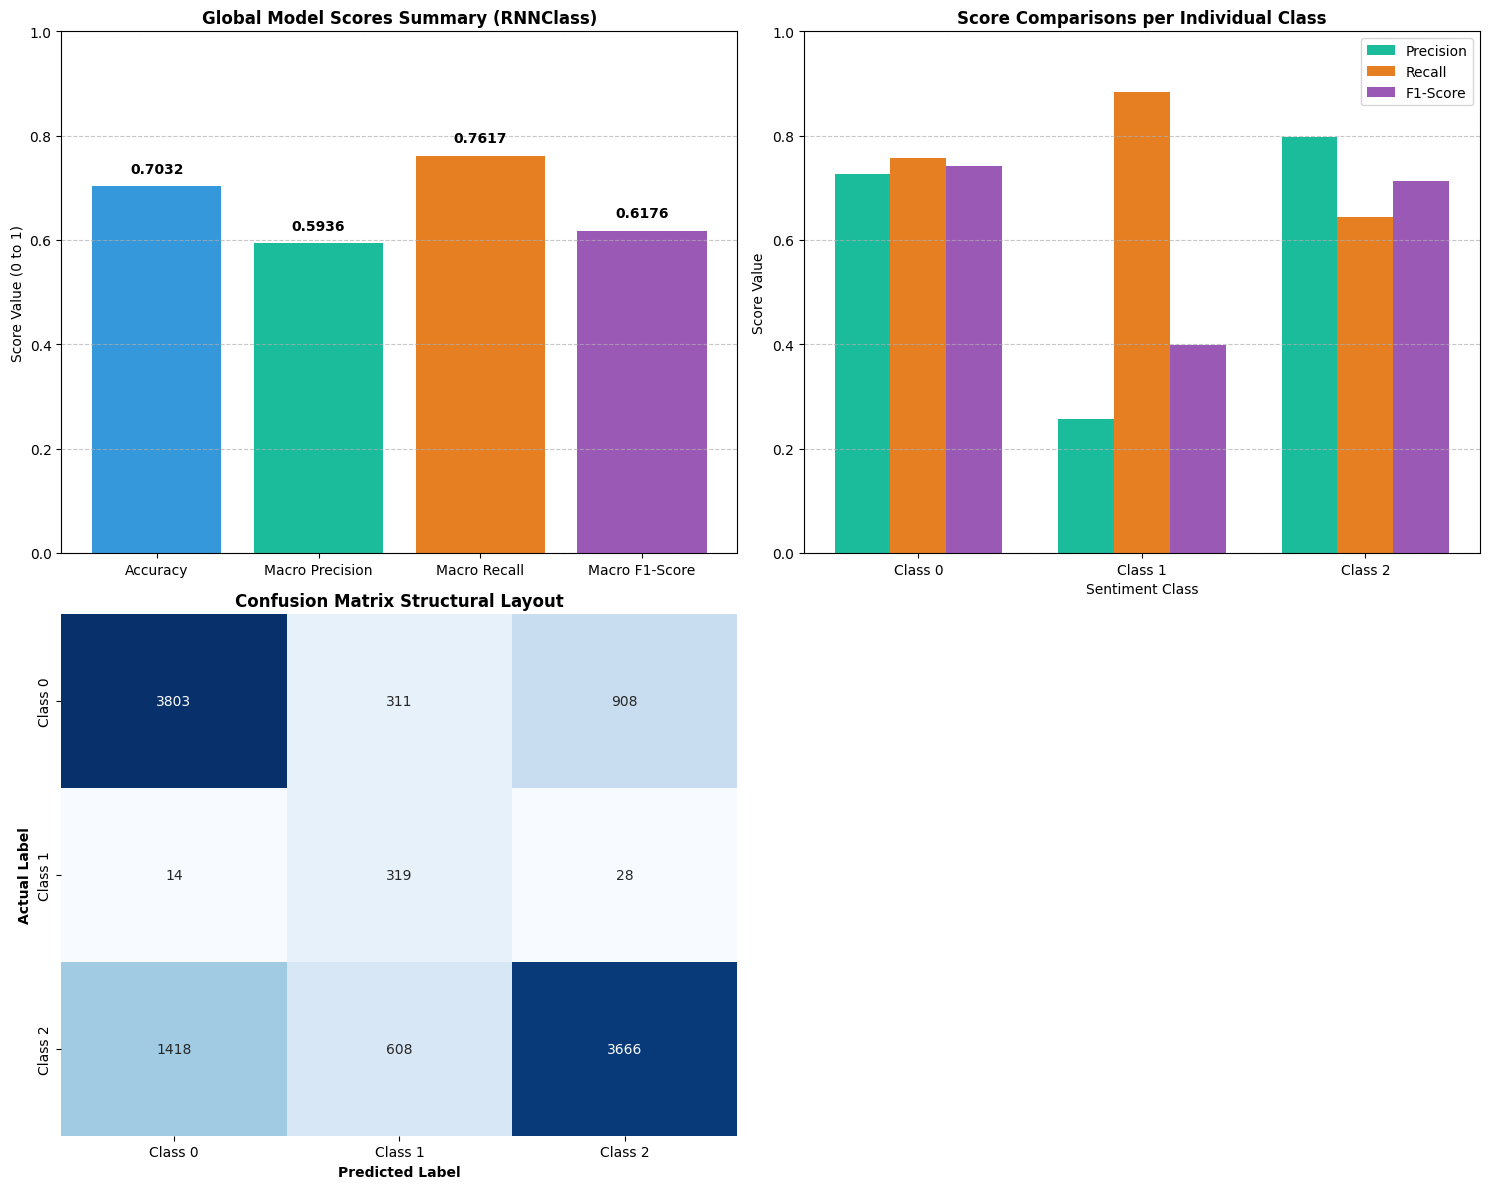


================ SYSTEM VERIFICATION TEXT REPORT (RNNClass) ================
              precision    recall  f1-score   support

     Class 0       0.73      0.76      0.74      5022
     Class 1       0.26      0.88      0.40       361
     Class 2       0.80      0.64      0.71      5692

    accuracy                           0.70     11075
   macro avg       0.59      0.76      0.62     11075
weighted avg       0.75      0.70      0.72     11075



In [ ]:
SELECTED_ARCH = "RNNClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

TEST_BATCH_SIZE = best_config["batch_size"]

test_loader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE, shuffle=False)

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

if SELECTED_ARCH == "LSTMClass":
    DROPOUT_RATE = min(best_config["dropout_rate"] + 0.15, 0.50)

else:
    DROPOUT_RATE = best_config["dropout_rate"]


OUTPUT_DIM    = 3

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)



checkpoint_path = f"best_{SELECTED_ARCH}_production_model.pt"

checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

model.load_state_dict(checkpoint['model_state_dict'])

print(f"Loaded optimal weights from epoch {checkpoint['epoch']} for final testing of {SELECTED_ARCH}.")

model.eval()

all_preds = []

all_labels = []

with torch.no_grad():

    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        logits = model(batch_x)

        _, predicted = torch.max(logits, 1)

        all_preds.extend(predicted.cpu().numpy())

        all_labels.extend(batch_y.cpu().numpy())

all_preds = np.array(all_preds)

all_labels = np.array(all_labels)

overall_accuracy = accuracy_score(all_labels, all_preds)

macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='macro'
)

precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
    all_labels, all_preds, average=None
)

rnn_preds = np.array(all_preds)
rnn_labels = np.array(all_labels)

test_f1_scores[SELECTED_ARCH] = macro_f1


#-------------------------------------------------


plt.figure(figsize=(15, 12))

# Plot 1:
plt.subplot(2, 2, 1)
summary_metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']
summary_values = [overall_accuracy, macro_precision, macro_recall, macro_f1]
bars = plt.bar(summary_metrics, summary_values, color=['#3498db', '#1abc9c', '#e67e22', '#9b59b6'])
plt.ylim(0, 1.0)
plt.title(f'Global Model Scores Summary ({SELECTED_ARCH})', fontsize=12, fontweight='bold')
plt.ylabel('Score Value (0 to 1)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2:
plt.subplot(2, 2, 2)
classes = ['Class 0', 'Class 1', 'Class 2']
x = np.arange(len(classes))
width = 0.25

plt.bar(x - width, precision_per_class, width, label='Precision', color='#1abc9c')
plt.bar(x, recall_per_class, width, label='Recall', color='#e67e22')
plt.bar(x + width, f1_per_class, width, label='F1-Score', color='#9b59b6')

plt.title('Score Comparisons per Individual Class', fontsize=12, fontweight='bold')
plt.xticks(x, classes)
plt.ylim(0, 1.0)
plt.xlabel('Sentiment Class')
plt.ylabel('Score Value')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 3:
plt.subplot(2, 2, 3)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('Actual Label', fontweight='bold')
plt.title('Confusion Matrix Structural Layout', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n================ SYSTEM VERIFICATION TEXT REPORT ({SELECTED_ARCH}) ================")
print(classification_report(all_labels, all_preds, target_names=['Class 0', 'Class 1', 'Class 2']))

Test on GRU:

Loaded optimal weights from epoch 15 for final testing of GRUClass.


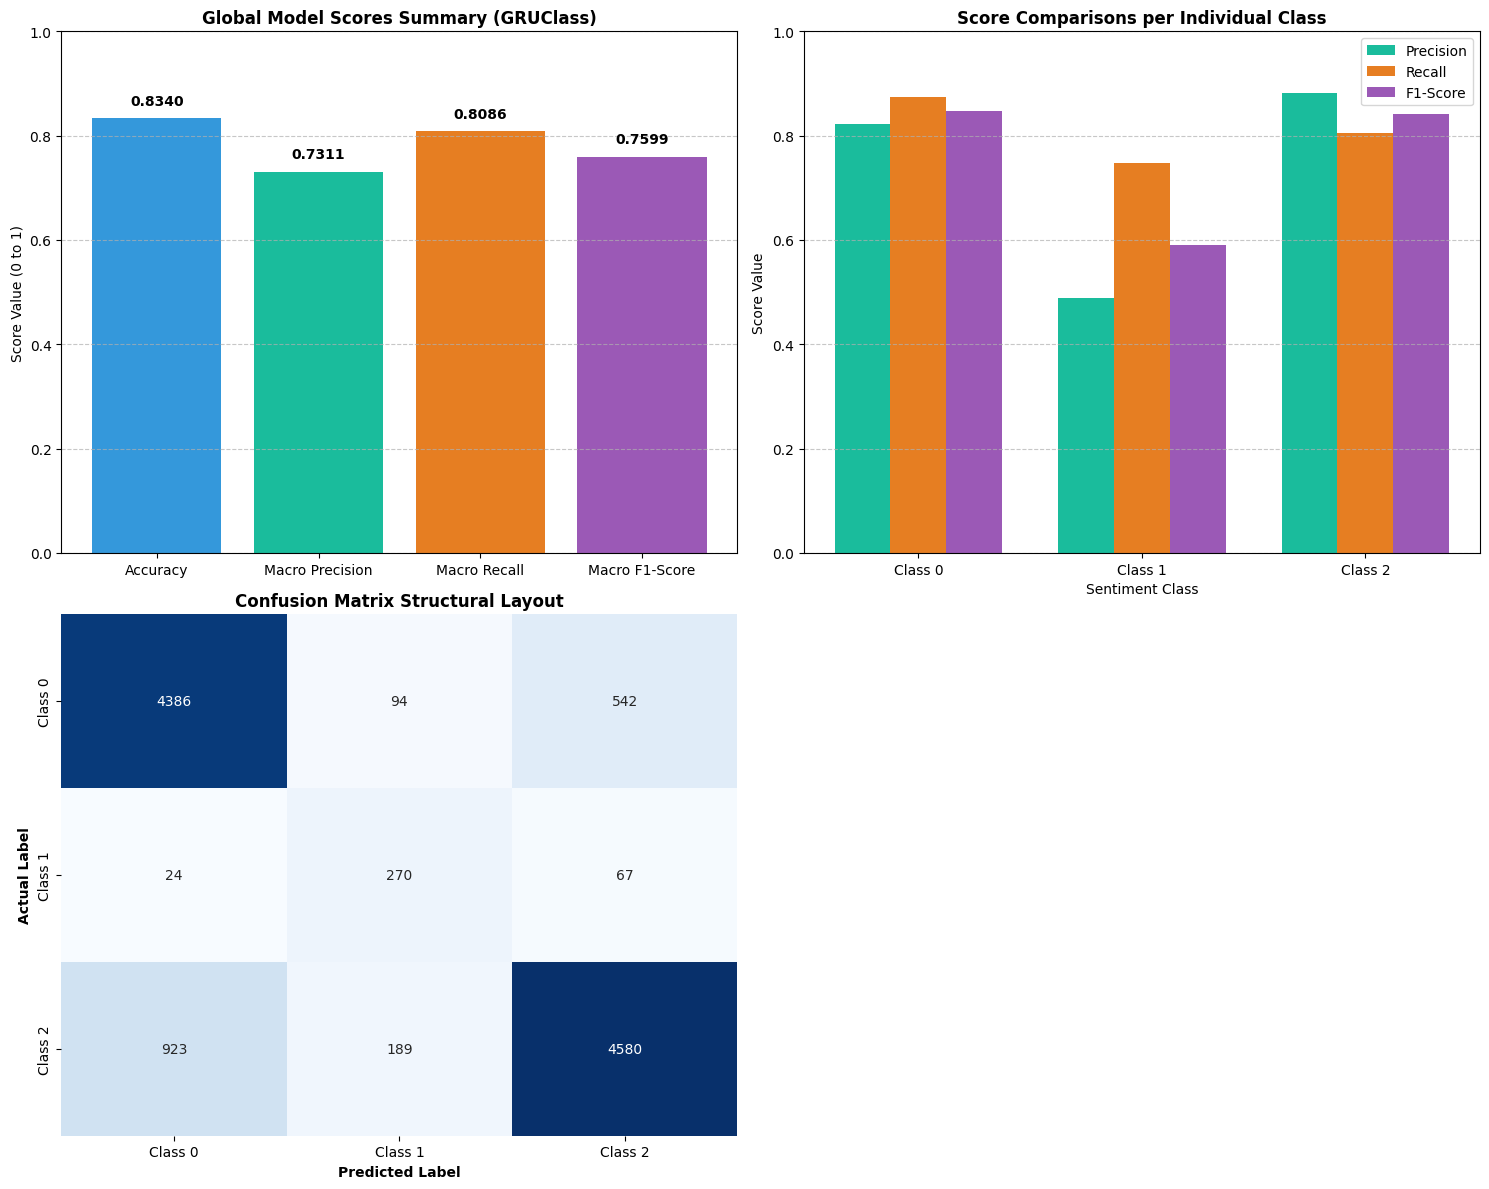


================ SYSTEM VERIFICATION TEXT REPORT (GRUClass) ================
              precision    recall  f1-score   support

     Class 0       0.82      0.87      0.85      5022
     Class 1       0.49      0.75      0.59       361
     Class 2       0.88      0.80      0.84      5692

    accuracy                           0.83     11075
   macro avg       0.73      0.81      0.76     11075
weighted avg       0.84      0.83      0.84     11075



In [ ]:
SELECTED_ARCH = "GRUClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

TEST_BATCH_SIZE = best_config["batch_size"]

test_loader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE, shuffle=False)

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

if SELECTED_ARCH == "LSTMClass":
    DROPOUT_RATE = min(best_config["dropout_rate"] + 0.15, 0.50)

else:
    DROPOUT_RATE = best_config["dropout_rate"]


OUTPUT_DIM    = 3

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)



checkpoint_path = f"best_{SELECTED_ARCH}_production_model.pt"

checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

model.load_state_dict(checkpoint['model_state_dict'])

print(f"Loaded optimal weights from epoch {checkpoint['epoch']} for final testing of {SELECTED_ARCH}.")

model.eval()

all_preds = []

all_labels = []

with torch.no_grad():

    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        logits = model(batch_x)

        _, predicted = torch.max(logits, 1)

        all_preds.extend(predicted.cpu().numpy())

        all_labels.extend(batch_y.cpu().numpy())

all_preds = np.array(all_preds)

all_labels = np.array(all_labels)

overall_accuracy = accuracy_score(all_labels, all_preds)

macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='macro'
)

precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
    all_labels, all_preds, average=None
)


gru_preds = np.array(all_preds)
gru_labels = np.array(all_labels)

test_f1_scores[SELECTED_ARCH] = macro_f1

#-------------------------------------------------


plt.figure(figsize=(15, 12))

# Plot 1:
plt.subplot(2, 2, 1)
summary_metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']
summary_values = [overall_accuracy, macro_precision, macro_recall, macro_f1]
bars = plt.bar(summary_metrics, summary_values, color=['#3498db', '#1abc9c', '#e67e22', '#9b59b6'])
plt.ylim(0, 1.0)
plt.title(f'Global Model Scores Summary ({SELECTED_ARCH})', fontsize=12, fontweight='bold')
plt.ylabel('Score Value (0 to 1)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2:
plt.subplot(2, 2, 2)
classes = ['Class 0', 'Class 1', 'Class 2']
x = np.arange(len(classes))
width = 0.25

plt.bar(x - width, precision_per_class, width, label='Precision', color='#1abc9c')
plt.bar(x, recall_per_class, width, label='Recall', color='#e67e22')
plt.bar(x + width, f1_per_class, width, label='F1-Score', color='#9b59b6')

plt.title('Score Comparisons per Individual Class', fontsize=12, fontweight='bold')
plt.xticks(x, classes)
plt.ylim(0, 1.0)
plt.xlabel('Sentiment Class')
plt.ylabel('Score Value')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 3:
plt.subplot(2, 2, 3)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('Actual Label', fontweight='bold')
plt.title('Confusion Matrix Structural Layout', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n================ SYSTEM VERIFICATION TEXT REPORT ({SELECTED_ARCH}) ================")
print(classification_report(all_labels, all_preds, target_names=['Class 0', 'Class 1', 'Class 2']))

Test on LSTM:

Loaded optimal weights from epoch 6 for final testing of LSTMClass.


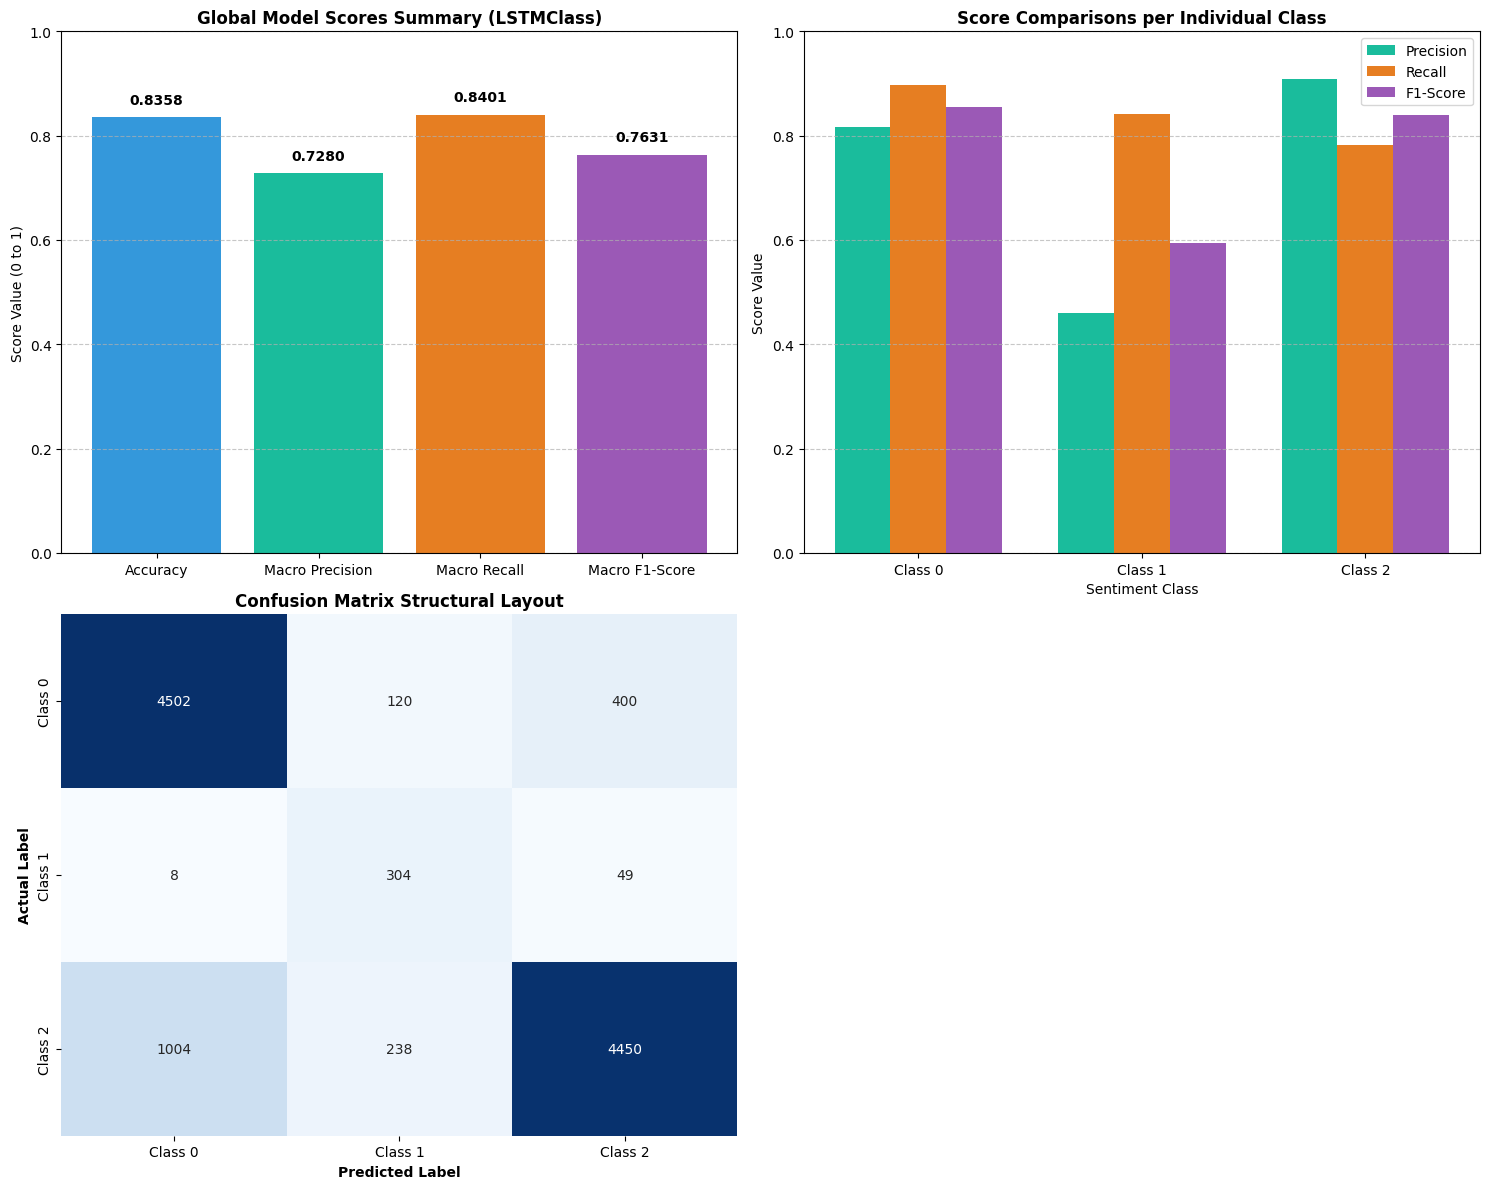


================ SYSTEM VERIFICATION TEXT REPORT (LSTMClass) ================
              precision    recall  f1-score   support

     Class 0       0.82      0.90      0.85      5022
     Class 1       0.46      0.84      0.59       361
     Class 2       0.91      0.78      0.84      5692

    accuracy                           0.84     11075
   macro avg       0.73      0.84      0.76     11075
weighted avg       0.85      0.84      0.84     11075



In [ ]:
SELECTED_ARCH = "LSTMClass"

best_config = global_best_profiles[SELECTED_ARCH]["best_config"]

TEST_BATCH_SIZE = best_config["batch_size"]

test_loader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE, shuffle=False)

VOCAB_SIZE    = vocab_size

EMBEDDING_DIM = 128

HIDDEN_DIM    = best_config["hidden_dim"]

NUM_LAYERS    = best_config["num_layers"]

if SELECTED_ARCH == "LSTMClass":
    DROPOUT_RATE = min(best_config["dropout_rate"] + 0.15, 0.50)

else:
    DROPOUT_RATE = best_config["dropout_rate"]


OUTPUT_DIM    = 3

model_mapping = {
    "RNNClass": RNNClass,
    "GRUClass": GRUClass,
    "LSTMClass": LSTMClass
}

model = model_mapping[SELECTED_ARCH](
    vocab_size = VOCAB_SIZE,
    embedding_dim = EMBEDDING_DIM,
    hidden_dim = HIDDEN_DIM,
    num_layers = NUM_LAYERS,
    dropout_rate = DROPOUT_RATE,
    output_dim = OUTPUT_DIM
).to(DEVICE)



checkpoint_path = f"best_{SELECTED_ARCH}_production_model.pt"

checkpoint = torch.load(checkpoint_path, map_location=DEVICE)

model.load_state_dict(checkpoint['model_state_dict'])

print(f"Loaded optimal weights from epoch {checkpoint['epoch']} for final testing of {SELECTED_ARCH}.")

model.eval()

all_preds = []

all_labels = []

with torch.no_grad():

    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)

        logits = model(batch_x)

        _, predicted = torch.max(logits, 1)

        all_preds.extend(predicted.cpu().numpy())

        all_labels.extend(batch_y.cpu().numpy())

all_preds = np.array(all_preds)

all_labels = np.array(all_labels)

overall_accuracy = accuracy_score(all_labels, all_preds)

macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
    all_labels, all_preds, average='macro'
)

precision_per_class, recall_per_class, f1_per_class, _ = precision_recall_fscore_support(
    all_labels, all_preds, average=None
)

lstm_preds = np.array(all_preds)
lstm_labels = np.array(all_labels)

test_f1_scores[SELECTED_ARCH] = macro_f1

#-------------------------------------------------


plt.figure(figsize=(15, 12))

# Plot 1:
plt.subplot(2, 2, 1)
summary_metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']
summary_values = [overall_accuracy, macro_precision, macro_recall, macro_f1]
bars = plt.bar(summary_metrics, summary_values, color=['#3498db', '#1abc9c', '#e67e22', '#9b59b6'])
plt.ylim(0, 1.0)
plt.title(f'Global Model Scores Summary ({SELECTED_ARCH})', fontsize=12, fontweight='bold')
plt.ylabel('Score Value (0 to 1)')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2:
plt.subplot(2, 2, 2)
classes = ['Class 0', 'Class 1', 'Class 2']
x = np.arange(len(classes))
width = 0.25

plt.bar(x - width, precision_per_class, width, label='Precision', color='#1abc9c')
plt.bar(x, recall_per_class, width, label='Recall', color='#e67e22')
plt.bar(x + width, f1_per_class, width, label='F1-Score', color='#9b59b6')

plt.title('Score Comparisons per Individual Class', fontsize=12, fontweight='bold')
plt.xticks(x, classes)
plt.ylim(0, 1.0)
plt.xlabel('Sentiment Class')
plt.ylabel('Score Value')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot 3:
plt.subplot(2, 2, 3)
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Class 0', 'Class 1', 'Class 2'],
            yticklabels=['Class 0', 'Class 1', 'Class 2'])
plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('Actual Label', fontweight='bold')
plt.title('Confusion Matrix Structural Layout', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n================ SYSTEM VERIFICATION TEXT REPORT ({SELECTED_ARCH}) ================")
print(classification_report(all_labels, all_preds, target_names=['Class 0', 'Class 1', 'Class 2']))

# Error analysis:

In [ ]:
TARGET_MODEL = "LSTM"

prediction_mapping = {
    "RNN": rnn_preds if 'rnn_preds' in locals() else None,
    "GRU": gru_preds if 'gru_preds' in locals() else None,
    "LSTM": lstm_preds if 'lstm_preds' in locals() else None
}

selected_preds = prediction_mapping.get(TARGET_MODEL)

test_indices = df_baseline_cleaned.index[-len(X_test):]

analysis_df = df_baseline_cleaned.loc[test_indices].copy()

analysis_df['Actual'] = y_test

analysis_df['Predicted'] = selected_preds

analysis_df['word_count'] = analysis_df['text'].astype(str).apply(lambda x: len(x.split()))


errors_df = analysis_df[analysis_df['Actual'] != analysis_df['Predicted']].copy()


mixed_connectors = ['ولی', 'اما', 'با این حال', 'اگرچه', 'منتها', 'بااینکه']
sarcasm_hints = ['دستتون درد نکنه', 'ممنون بابت', 'عالی بود ولی', 'خدا خیرتون بده', 'چه عجب', 'توقع نداشتم']


sample_num = 0

def log_error_sample(row, category):

    global sample_num

    sample_num += 1

    print(f"\n[نمونه {sample_num}] دسته‌بندی خطای : {category}")
    print({row['text']})
    print(f"  [برچسب واقعی: {row['Actual']} | پیش‌بینی مدل : {row['Predicted']}]")

# Short Comments
short_pool = errors_df[errors_df['word_count'] <= 3].head(2)
for _, row in short_pool.iterrows():
    log_error_sample(row, "  نظرات کوتاه (Short Comments)")

# Class Imbalance Effects
imbalance_pool = errors_df[(errors_df['Actual'] != 1) & (errors_df['Predicted'] == 1)].head(2)
for _, row in imbalance_pool.iterrows():
    log_error_sample(row, "اثرات عدم توازن کلاس‌ها (Class Imbalance Bias)")

# Mixed Sentiment
mixed_mask = errors_df['text'].astype(str).apply(lambda x: any(w in x for w in mixed_connectors))
mixed_pool = errors_df[mixed_mask].head(2)
for _, row in mixed_pool.iterrows():
    log_error_sample(row, "موارد احساسی گیج‌کننده (Mixed Sentiment)")

# Sarcasm or Ambiguity
sarcasm_mask = errors_df['text'].astype(str).apply(lambda x: any(w in x for w in sarcasm_hints))
sarcasm_pool = errors_df[sarcasm_mask].head(2)
if len(sarcasm_pool) < 2:
    sarcasm_pool = pd.concat([sarcasm_pool, errors_df[(errors_df['word_count'] >= 6) & (errors_df['word_count'] <= 12)].head(2 - len(sarcasm_pool))])
for _, row in sarcasm_pool.iterrows():
    log_error_sample(row, "کنایه یا نظرات مبهم (Sarcasm & Pragmatic Ambiguity)")

# Data Quality Issues
quality_mask = errors_df['text'].astype(str).str.contains(r'[a-zA-Z]|!{2,}|\?{2,}|_', regex=True)
quality_pool = errors_df[quality_mask].head(2)
for _, row in quality_pool.iterrows():
    log_error_sample(row, "مشکلات کیفیت داده (Data Quality & Noise Artifacts)")



[نمونه 1] دسته‌بندی خطای :   نظرات کوتاه (Short Comments)
{'من سفارش دادم.'}
  [برچسب واقعی: 2 | پیش‌بینی مدل : 0]

[نمونه 2] دسته‌بندی خطای :   نظرات کوتاه (Short Comments)
{'گوشیه بسیار خوبیه.'}
  [برچسب واقعی: 0 | پیش‌بینی مدل : 2]

[نمونه 3] دسته‌بندی خطای : اثرات عدم توازن کلاس‌ها (Class Imbalance Bias)
{'پیتزا سبزیجات خیلی بد بود. خیلی بد'}
  [برچسب واقعی: 0 | پیش‌بینی مدل : 1]

[نمونه 4] دسته‌بندی خطای : اثرات عدم توازن کلاس‌ها (Class Imbalance Bias)
{'تاخیر بسیار زیاد از طرف فروشگاه!!'}
  [برچسب واقعی: 2 | پیش‌بینی مدل : 1]

[نمونه 5] دسته‌بندی خطای : موارد احساسی گیج‌کننده (Mixed Sentiment)
{'نصف آبمیوه ترش ریخته بود که احتمالا در راه این اتفاق افتاده، ولی مزه ها عالی بود'}
  [برچسب واقعی: 0 | پیش‌بینی مدل : 2]

[نمونه 6] دسته‌بندی خطای : موارد احساسی گیج‌کننده (Mixed Sentiment)
{'نظر ما رو که تو سایت نمیذارین ولی پیتزا پنیر بود به جای پیتزا استیک! پیتزا کاملا خیس بود نونش و چسبیده بود به کاغذ در حدی که جدا نمی شد.'}
  [برچسب واقعی: 2 | پیش‌بینی مدل : 0]

[نمونه 7] دسته‌بندی 

# Comparing the models:

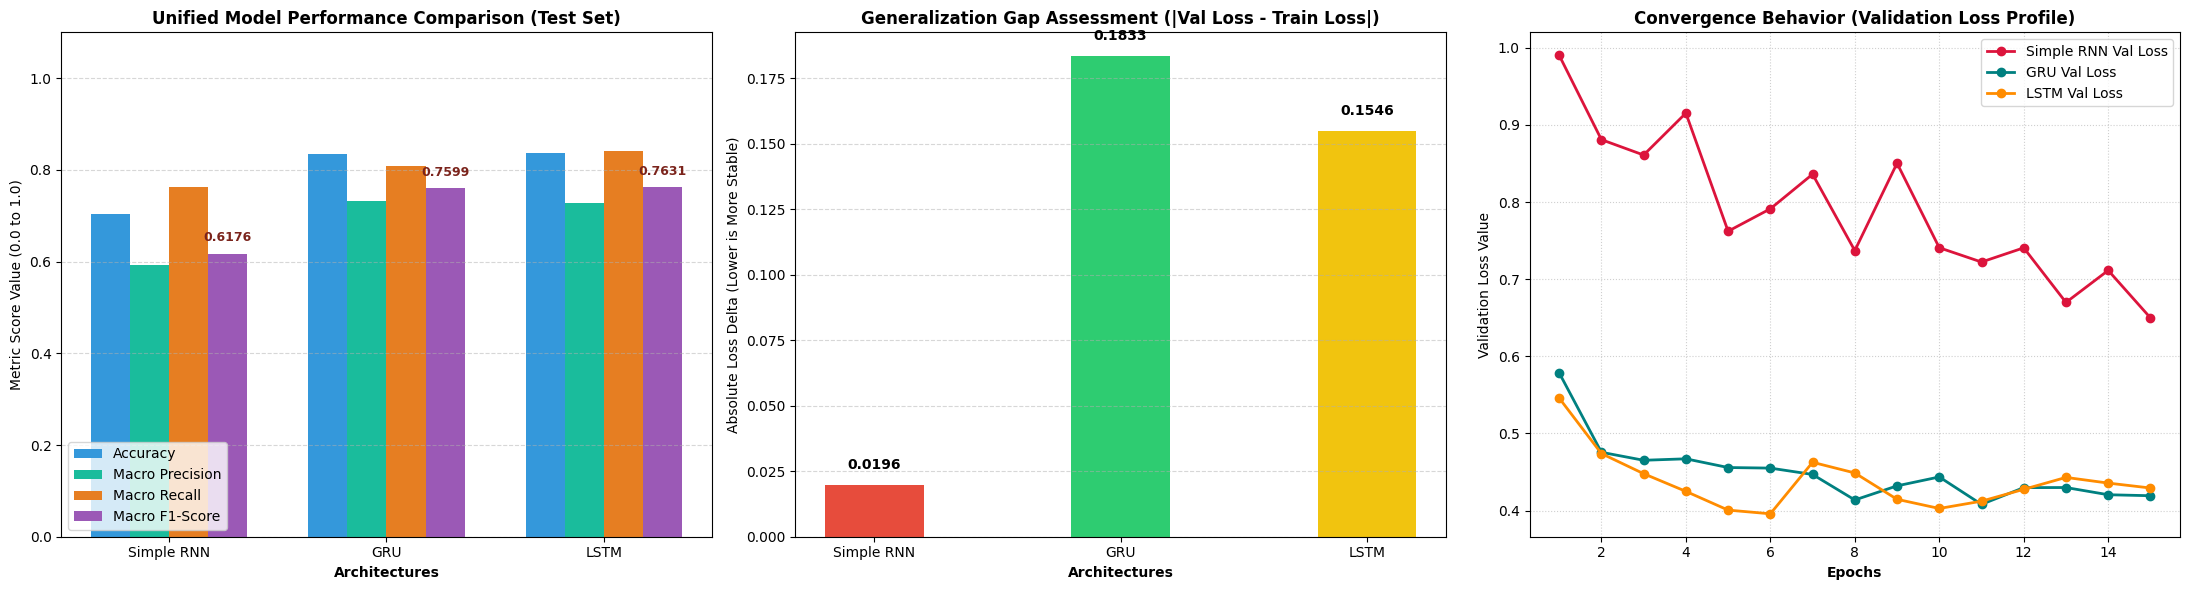

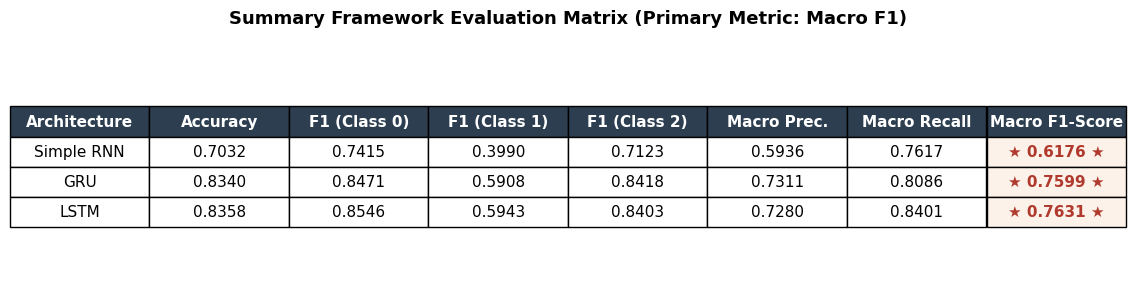

In [ ]:
models_to_compare = ["RNNClass", "GRUClass", "LSTMClass"]
display_names = ["Simple RNN", "GRU", "LSTM"]

prediction_mapping = {
    "RNNClass": rnn_preds if 'rnn_preds' in locals() else None,
    "GRUClass": gru_preds if 'gru_preds' in locals() else None,
    "LSTMClass": lstm_preds if 'lstm_preds' in locals() else None
}

accuracies, precisions, recalls, f1_scores = [], [], [], []
generalization_gaps = []
table_data = []

for m_key, d_name in zip(models_to_compare, display_names):
    preds = prediction_mapping.get(m_key)

    if preds is not None:
        acc = accuracy_score(all_labels, preds)
        macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(all_labels, preds, average='macro')

        accuracies.append(acc)
        precisions.append(macro_p)
        recalls.append(macro_r)
        f1_scores.append(macro_f1)

        f1_per_class = precision_recall_fscore_support(all_labels, preds, average=None)[2]

        table_data.append([
            d_name,
            f"{acc:.4f}",
            f"{f1_per_class[0]:.4f}",
            f"{f1_per_class[1]:.4f}",
            f"{f1_per_class[2]:.4f}",
            f"{macro_p:.4f}",
            f"{macro_r:.4f}",
            f"★ {macro_f1:.4f} ★"
        ])
    else:
        accuracies.append(0.0)
        precisions.append(0.0)
        recalls.append(0.0)
        f1_scores.append(0.0)
        table_data.append([d_name] + ["N/A"] * 7)

    if 'all_model_history' in locals() and m_key in all_model_history:
        final_train_loss = all_model_history[m_key]['train_losses'][-1]
        final_val_loss = all_model_history[m_key]['val_losses'][-1]
        generalization_gaps.append(abs(final_val_loss - final_train_loss))
    else:
        generalization_gaps.append(0.0)

#----------------------------

plt.figure(figsize=(22, 6))

plt.subplot(1, 3, 1)
x = np.arange(len(display_names))
width = 0.18

plt.bar(x - 1.5*width, accuracies, width, label='Accuracy', color='#3498db')
plt.bar(x - 0.5*width, precisions, width, label='Macro Precision', color='#1abc9c')
plt.bar(x + 0.5*width, recalls, width, label='Macro Recall', color='#e67e22')
plt.bar(x + 1.5*width, f1_scores, width, label='Macro F1-Score', color='#9b59b6')

plt.title('Unified Model Performance Comparison (Test Set)', fontsize=12, fontweight='bold')
plt.xticks(x, display_names)
plt.xlabel('Architectures', fontweight='bold')
plt.ylabel('Metric Score Value (0.0 to 1.0)')
plt.ylim(0, 1.1)
plt.legend(loc='lower left')
plt.grid(axis='y', linestyle='--', alpha=0.5)

for i, val in enumerate(f1_scores):
    if val > 0:
        plt.text(i + 1.5*width, val + 0.02, f'{val:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#7b241c')

#----------------------------

plt.subplot(1, 3, 2)
bars = plt.bar(display_names, generalization_gaps, color=['#e74c3c', '#2ecc71', '#f1c40f'], width=0.4)
plt.title('Generalization Gap Assessment (|Val Loss - Train Loss|)', fontsize=12, fontweight='bold')
plt.xlabel('Architectures', fontweight='bold')
plt.ylabel('Absolute Loss Delta (Lower is More Stable)')
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    if yval > 0:
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.005, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')


#----------------------------

plt.subplot(1, 3, 3)
colors_map = {'RNNClass': 'crimson', 'GRUClass': 'teal', 'LSTMClass': 'darkorange'}

if 'all_model_history' in locals() and len(all_model_history) > 0:
    for m_key, d_name in zip(models_to_compare, display_names):
        if m_key in all_model_history:
            val_losses = all_model_history[m_key]['val_losses']
            epochs = range(1, len(val_losses) + 1)
            plt.plot(epochs, val_losses, label=f'{d_name} Val Loss', color=colors_map[m_key], marker='o', linewidth=2)
    plt.title('Convergence Behavior (Validation Loss Profile)', fontsize=12, fontweight='bold')
    plt.xlabel('Epochs', fontweight='bold')
    plt.ylabel('Validation Loss Value')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
else:
    plt.text(0.5, 0.5, 'all_model_history not found\nCannot plot convergence', ha='center', va='center', fontsize=12)
    plt.title('Convergence Behavior (Missing Data Context)')

plt.tight_layout()
plt.show()

#----------------------------

columns = [
    "Architecture", "Accuracy", "F1 (Class 0)", "F1 (Class 1)",
    "F1 (Class 2)", "Macro Prec.", "Macro Recall", "Macro F1-Score"
]

fig, ax = plt.subplots(figsize=(12, 3))
ax.axis('tight')
ax.axis('off')

vis_table = ax.table(
    cellText=table_data,
    colLabels=columns,
    cellLoc='center',
    loc='center',
    colColours=['#2c3e50'] * len(columns)
)

vis_table.auto_set_font_size(False)
for (i, j), cell in vis_table.get_celld().items():
    cell.set_fontsize(11)
vis_table.scale(1.2, 1.8)

for j in range(len(columns)):
    vis_table[0, j].get_text().set_color('white')
    vis_table[0, j].get_text().set_weight('bold')

for i in range(1, len(table_data) + 1):
    vis_table[i, 7].set_facecolor('#fdf2e9')
    vis_table[i, 7].get_text().set_weight('bold')
    vis_table[i, 7].get_text().set_color('#b03a2e')

plt.title("Summary Framework Evaluation Matrix (Primary Metric: Macro F1)", fontsize=13, weight='bold', pad=20)
plt.show()

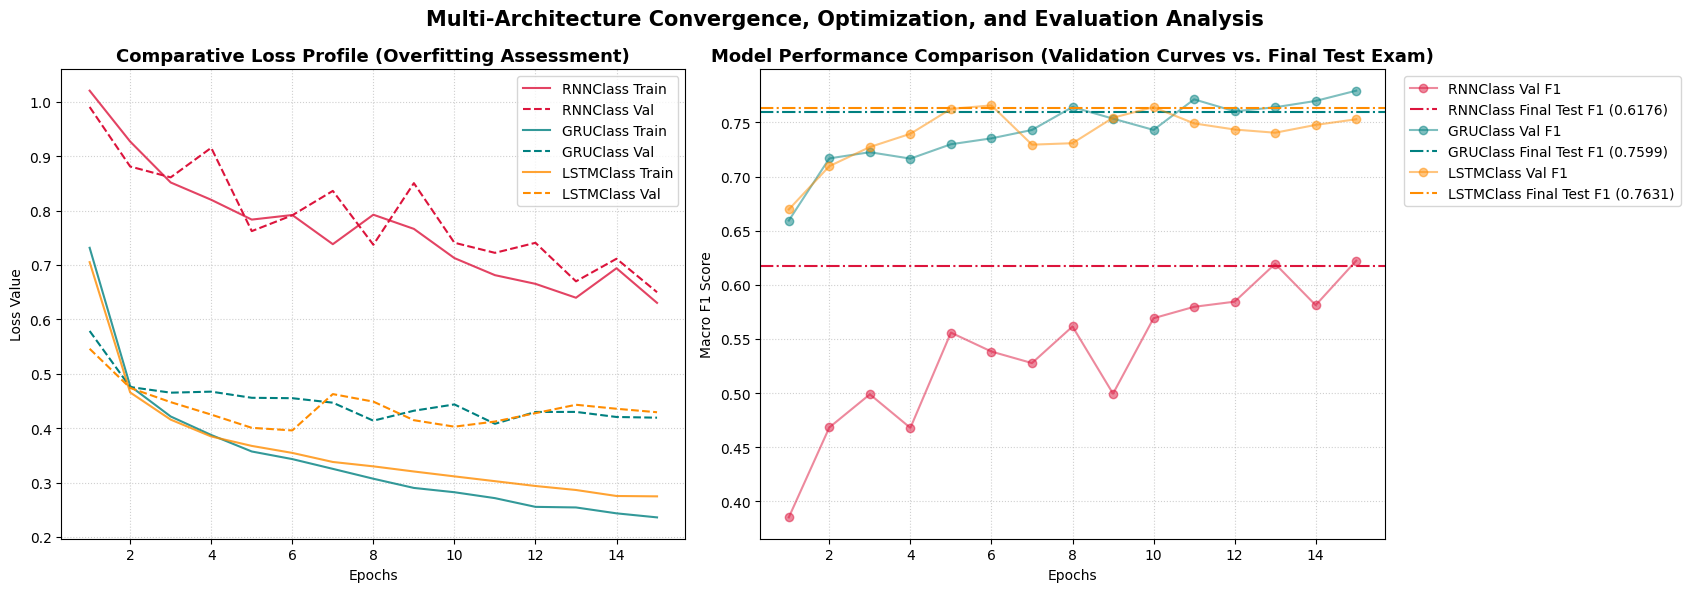

In [ ]:
epochs_range = range(1, 16)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))

colors = {'RNNClass': 'crimson', 'GRUClass': 'teal', 'LSTMClass': 'darkorange'}

for model_name, metrics in all_model_history.items():

    axes[0].plot(epochs_range, metrics['train_losses'], label=f'{model_name} Train', color=colors[model_name], alpha=0.8)
    axes[0].plot(epochs_range, metrics['val_losses'], label=f'{model_name} Val', linestyle='--', color=colors[model_name])

axes[0].set_title('Comparative Loss Profile (Overfitting Assessment)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss Value')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)


for model_name, metrics in all_model_history.items():

    axes[1].plot(epochs_range, metrics['val_f1s'], label=f'{model_name} Val F1', color=colors[model_name], marker='o', alpha=0.5)

    final_test_score = test_f1_scores.get(model_name)
    if final_test_score is not None:
        axes[1].axhline(y=final_test_score, color=colors[model_name], linestyle='-.', linewidth=1.5,
                        label=f'{model_name} Final Test F1 ({final_test_score:.4f})')

axes[1].set_title('Model Performance Comparison (Validation Curves vs. Final Test Exam)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Macro F1 Score')

axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Multi-Architecture Convergence, Optimization, and Evaluation Analysis', fontsize=15, weight='bold')
plt.tight_layout()
plt.show()

# Fine tuning ParsBERT:

In [ ]:
raw_text_series = df['Cleaned Review'].values

text_train, text_temp, _, _, _, strat_temp_text = train_test_split(
    raw_text_series, labels, df['stratify_key'],
    test_size=0.3, random_state=42, stratify=df['stratify_key']
)

text_val, text_test, _, _ = train_test_split(
    text_temp, y_temp,
    test_size=0.5, random_state=42, stratify=strat_temp
)

train_ds = Dataset.from_dict({"text": text_train.tolist(), "label": y_train})

val_ds   = Dataset.from_dict({"text": text_val.tolist(), "label": y_val})

test_ds  = Dataset.from_dict({"text": text_test.tolist(), "label": y_test})


MODEL_NAME = "HooshvareLab/bert-fa-zwnj-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def preprocess_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=128)

tokenized_train = train_ds.map(preprocess_function, batched=True)

tokenized_val   = val_ds.map(preprocess_function, batched=True)

tokenized_test  = test_ds.map(preprocess_function, batched=True)

# Dynamic batch padding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return metric.compute(predictions=predictions, references=labels, average="macro")

#defining the pre-trained model we want to use
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3)


training_args = TrainingArguments(
    output_dir = "./results_parsbert",
    learning_rate = 2e-5,
    per_device_train_batch_size = 16,
    per_device_eval_batch_size = 16,
    num_train_epochs = 3,
    weight_decay = 0.01,
    eval_strategy = "epoch",
    save_strategy = "epoch",
    load_best_model_at_end = True,
    metric_for_best_model = "f1",
    logging_steps = 50,
    fp16 = torch.cuda.is_available(),
    report_to = "none"
)

trainer = Trainer(
    model = model,
    args = training_args,
    train_dataset = tokenized_train,
    eval_dataset = tokenized_val,
    processing_class = tokenizer,
    data_collator = data_collator,
    compute_metrics = compute_metrics,
)


#training
trainer.train()


#evaluation
predictions_output = trainer.predict(tokenized_test)

parsbert_preds = np.argmax(predictions_output.predictions, axis=1)

parsbert_labels = predictions_output.label_ids

prediction_mapping["ParsBERTClass"] = parsbert_preds


print("\n================ SYSTEM VERIFICATION TEXT REPORT (ParsBERT) ================")
print(classification_report(parsbert_labels, parsbert_preds, target_names=['Class 0', 'Class 1', 'Class 2']))

Map:   0%|          | 0/51679 [00:00<?, ? examples/s]

Map:   0%|          | 0/11074 [00:00<?, ? examples/s]

Map:   0%|          | 0/11075 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: HooshvareLab/bert-fa-zwnj-base
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

Epoch,Training Loss,Validation Loss,F1
1,0.400486,0.376915,0.760903
2,0.331873,0.363699,0.802625
3,0.284776,0.393997,0.803527


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


================ SYSTEM VERIFICATION TEXT REPORT (ParsBERT) ================
              precision    recall  f1-score   support

     Class 0       0.83      0.87      0.85      5022
     Class 1       0.71      0.61      0.66       361
     Class 2       0.87      0.83      0.85      5692

    accuracy                           0.84     11075
   macro avg       0.80      0.77      0.78     11075
weighted avg       0.84      0.84      0.84     11075



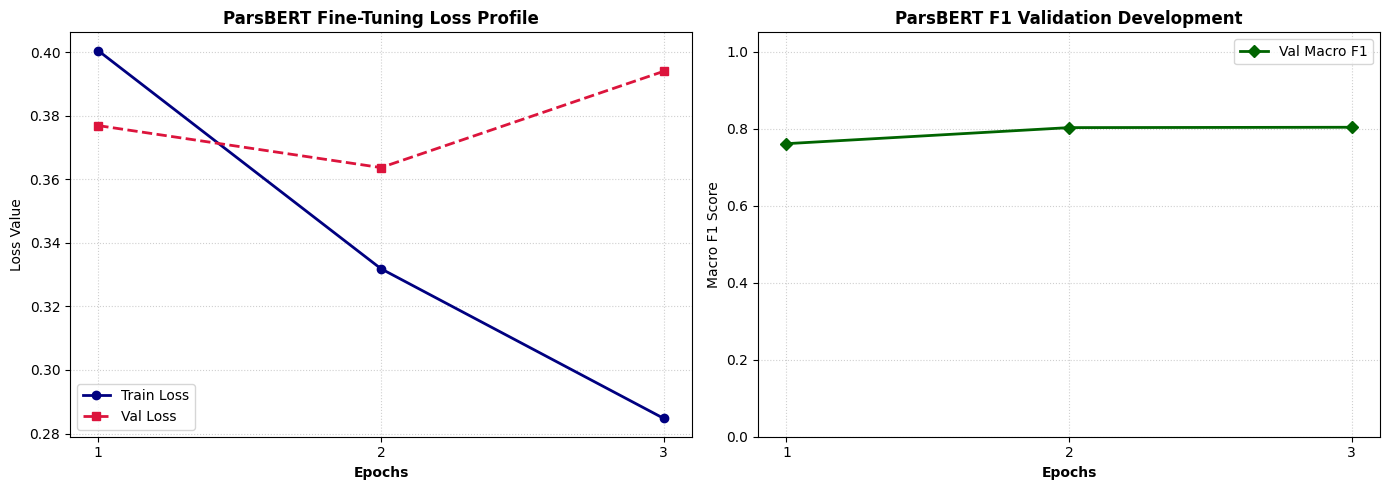

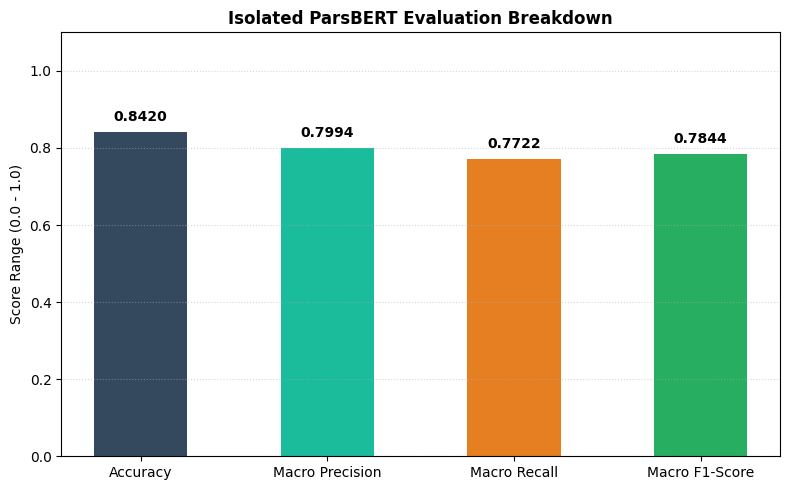

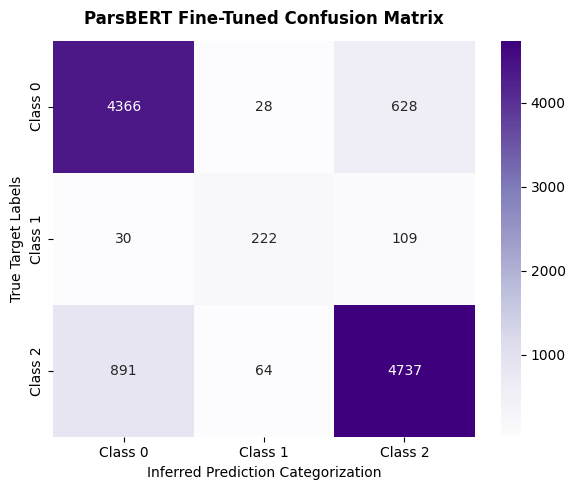

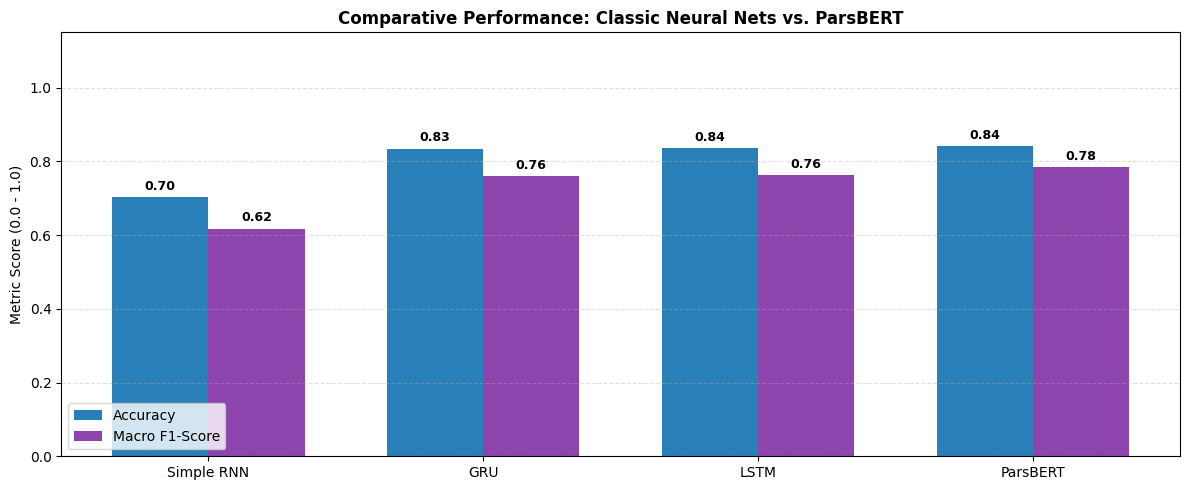

In [ ]:
extended_models = ["RNNClass", "GRUClass", "LSTMClass", "ParsBERTClass"]
extended_display = ["Simple RNN", "GRU", "LSTM", "ParsBERT"]

epochs_logged = [1, 2, 3]
train_loss_track = [0.400486, 0.331873, 0.284776]
val_loss_track = [0.376915, 0.363699, 0.393997]
val_f1_track = [0.760903, 0.802625, 0.803527]

all_acc, all_f1 = [], []
for m_key in extended_models:
    preds = prediction_mapping.get(m_key)
    if preds is not None:
        all_acc.append(accuracy_score(all_labels, preds))
        _, _, f, _ = precision_recall_fscore_support(all_labels, preds, average='macro')
        all_f1.append(f)
    else:
        all_acc.append(0.0)
        all_f1.append(0.0)

pb_preds = prediction_mapping.get("ParsBERTClass")
if pb_preds is not None:
    pb_acc = accuracy_score(all_labels, pb_preds)
    pb_prec, pb_rec, pb_f1, _ = precision_recall_fscore_support(all_labels, pb_preds, average='macro')
else:
    pb_acc, pb_prec, pb_rec, pb_f1 = 0.84, 0.80, 0.77, 0.78  # Exact values from your verification report

#-------------------

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_logged, train_loss_track, 'o-', color='navy', label='Train Loss', linewidth=2)
plt.plot(epochs_logged, val_loss_track, 's--', color='crimson', label='Val Loss', linewidth=2)
plt.title('ParsBERT Fine-Tuning Loss Profile', fontweight='bold')
plt.xlabel('Epochs', fontweight='bold')
plt.ylabel('Loss Value')
plt.xticks(epochs_logged)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_logged, val_f1_track, 'D-', color='darkgreen', label='Val Macro F1', linewidth=2)
plt.title('ParsBERT F1 Validation Development', fontweight='bold')
plt.xlabel('Epochs', fontweight='bold')
plt.ylabel('Macro F1 Score')
plt.xticks(epochs_logged)
plt.ylim(0, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

#-------------------

plt.figure(figsize=(8, 5))
metrics_tags = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']
metrics_vals = [pb_acc, pb_prec, pb_rec, pb_f1]
colors_list = ['#34495e', '#1abc9c', '#e67e22', '#27ae60']

bars = plt.bar(metrics_tags, metrics_vals, color=colors_list, width=0.5)
plt.title('Isolated ParsBERT Evaluation Breakdown', fontsize=12, fontweight='bold')
plt.ylabel('Score Range (0.0 - 1.0)')
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle=':', alpha=0.5)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, h + 0.02, f'{h:.4f}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()


#-------------------

if pb_preds is not None:
    cm = confusion_matrix(all_labels, pb_preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
                xticklabels=['Class 0', 'Class 1', 'Class 2'],
                yticklabels=['Class 0', 'Class 1', 'Class 2'])
    plt.title('ParsBERT Fine-Tuned Confusion Matrix', fontweight='bold', pad=12)
    plt.ylabel('True Target Labels')
    plt.xlabel('Inferred Prediction Categorization')
    plt.tight_layout()
    plt.show()
else:
    print("Run predictions variable mapping to display final confusion matrix heatmap.")



    #-------------------

plt.figure(figsize=(12, 5))
x_idx = np.arange(len(extended_display))
w = 0.35

plt.bar(x_idx - w/2, all_acc, w, label='Accuracy', color='#2980b9')
plt.bar(x_idx + w/2, all_f1, w, label='Macro F1-Score', color='#8e44ad')

plt.title('Comparative Performance: Classic Neural Nets vs. ParsBERT', fontsize=12, fontweight='bold')
plt.xticks(x_idx, extended_display)
plt.ylabel('Metric Score (0.0 - 1.0)')
plt.ylim(0, 1.15)
plt.legend(loc='lower left')
plt.grid(axis='y', linestyle='--', alpha=0.4)

for i, (acc, f1) in enumerate(zip(all_acc, all_f1)):
    if acc > 0: plt.text(i - w/2, acc + 0.02, f'{acc:.2f}', ha='center', fontweight='bold', fontsize=9)
    if f1 > 0: plt.text(i + w/2, f1 + 0.02, f'{f1:.2f}', ha='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

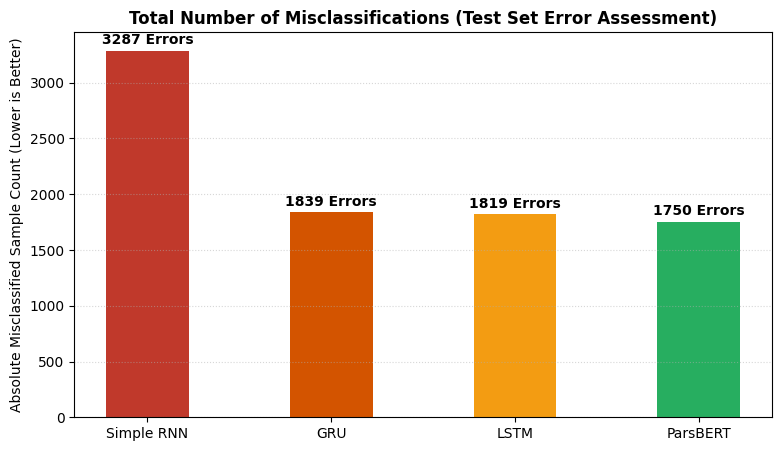

In [ ]:
extended_models = ["RNNClass", "GRUClass", "LSTMClass", "ParsBERTClass"]
extended_display = ["Simple RNN", "GRU", "LSTM", "ParsBERT"]

error_rates = []

for m_key in extended_models:
    preds = prediction_mapping.get(m_key)
    if preds is not None:
        total_errors = np.sum(preds != all_labels)
        error_rates.append(total_errors)
    else:
        error_rates.append(0)

plt.figure(figsize=(9, 5))
error_bars = plt.bar(extended_display, error_rates, color=['#c0392b', '#d35400', '#f39c12', '#27ae60'], width=0.45)
plt.title('Total Number of Misclassifications (Test Set Error Assessment)', fontsize=12, fontweight='bold')
plt.ylabel('Absolute Misclassified Sample Count (Lower is Better)')
plt.grid(axis='y', linestyle=':', alpha=0.5)

for b in error_bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2.0, h + (max(error_rates) * 0.01), f'{int(h)} Errors', ha='center', va='bottom', fontweight='bold')
plt.show()

In [ ]:
TARGET_MODEL = "ParsBERTClass"

prediction_mapping = {
    "RNNClass": prediction_mapping.get("RNNClass") if 'prediction_mapping' in locals() else None,
    "GRUClass": prediction_mapping.get("GRUClass") if 'prediction_mapping' in locals() else None,
    "LSTMClass": prediction_mapping.get("LSTMClass") if 'prediction_mapping' in locals() else None,
    "ParsBERTClass": prediction_mapping.get("ParsBERTClass") if 'prediction_mapping' in locals() else pb_preds
}

selected_preds = prediction_mapping.get(TARGET_MODEL)

if selected_preds is None:
    raise ValueError(f"Could not find predictions for {TARGET_MODEL}. Ensure 'prediction_mapping[\"ParsBERTClass\"]' or 'pb_preds' is loaded.")

test_indices = df_baseline_cleaned.index[-len(selected_preds):]

analysis_df = df_baseline_cleaned.loc[test_indices].copy()

analysis_df['Actual'] = all_labels

analysis_df['Predicted'] = selected_preds

analysis_df['word_count'] = analysis_df['text'].astype(str).apply(lambda x: len(x.split()))

errors_df = analysis_df[analysis_df['Actual'] != analysis_df['Predicted']].copy()


mixed_connectors = ['ولی', 'اما', 'با این حال', 'اگرچه', 'منتها', 'بااینکه', 'با این‌که']

sarcasm_hints = ['دستتون درد نکنه', 'ممنون بابت', 'عالی بود ولی', 'خدا خیرتون بده', 'چه عجب', 'توقع نداشتم']

sample_num = 0

def log_error_sample(row, category):
    global sample_num
    sample_num += 1
    print(f"\n[نمونه {sample_num}]{category}")
    print(f"{row['text']}")
    print(f"  [برچسب واقعی: {int(row['Actual'])} | پیش‌بینی پارس‌برت: {int(row['Predicted'])} | تعداد کلمات: {row['word_count']}]")


#  Short Comments
short_pool = errors_df[errors_df['word_count'] <= 3].head(2)
for _, row in short_pool.iterrows():
    log_error_sample(row, "(Short Context / Sparsity)")

#  Class Imbalance Effects
imbalance_pool = errors_df[(errors_df['Actual'] != 1) & (errors_df['Predicted'] == 1)].head(2)
for _, row in imbalance_pool.iterrows():
    log_error_sample(row, "(Class Imbalance Bias / False Positives)")

#  Mixed Sentiment
mixed_mask = errors_df['text'].astype(str).apply(lambda x: any(w in x for w in mixed_connectors))
mixed_pool = errors_df[mixed_mask].head(2)
for _, row in mixed_pool.iterrows():
    log_error_sample(row, " (Mixed Sentiment & Structural Shift)")

#  Sarcasm or Ambiguity
sarcasm_mask = errors_df['text'].astype(str).apply(lambda x: any(w in x for w in sarcasm_hints))
sarcasm_pool = errors_df[sarcasm_mask].head(2)
if len(sarcasm_pool) < 2:
    filler_needed = 2 - len(sarcasm_pool)
    fallback_texts = errors_df[(errors_df['word_count'] >= 6) & (errors_df['word_count'] <= 14)].head(filler_needed)
    sarcasm_pool = pd.concat([sarcasm_pool, fallback_texts])

for _, row in sarcasm_pool.iterrows():
    log_error_sample(row, "(Sarcasm & Pragmatic Ambiguity)")

# Data Quality & Noise Artifacts
quality_mask = errors_df['text'].astype(str).str.contains(r'[a-zA-Z]|!{2,}|\?{2,}|_', regex=True)
quality_pool = errors_df[quality_mask].head(2)
for _, row in quality_pool.iterrows():
    log_error_sample(row, "(Data Quality & Noise Artifacts)")



[نمونه 1](Short Context / Sparsity)
واقعا محشره.
  [برچسب واقعی: 0 | پیش‌بینی پارس‌برت: 2 | تعداد کلمات: 2]

[نمونه 2](Short Context / Sparsity)
نقاط قوت: 1.
  [برچسب واقعی: 0 | پیش‌بینی پارس‌برت: 2 | تعداد کلمات: 3]

[نمونه 3](Class Imbalance Bias / False Positives)
واقعا طعم و بوی مناسبی نداشت همبرگرش
  [برچسب واقعی: 0 | پیش‌بینی پارس‌برت: 1 | تعداد کلمات: 7]

[نمونه 4](Class Imbalance Bias / False Positives)
نوشته آدامس ولی خوشبوکننده دهانه. ….
  [برچسب واقعی: 2 | پیش‌بینی پارس‌برت: 1 | تعداد کلمات: 6]

[نمونه 5] (Mixed Sentiment & Structural Shift)
همه پیتزا ها خوشمزه و ولی یکم الکی گران بودند
  [برچسب واقعی: 2 | پیش‌بینی پارس‌برت: 0 | تعداد کلمات: 10]

[نمونه 6] (Mixed Sentiment & Structural Shift)
خوشمزه و عالی، اما بنظرم یه کم زیادی چرب و پر روغن بود
  [برچسب واقعی: 2 | پیش‌بینی پارس‌برت: 0 | تعداد کلمات: 13]

[نمونه 7](Sarcasm & Pragmatic Ambiguity)
اونقدر خوب بود که من دو روز پیاپی سفارش دادم ممنون بابت کیفیت خوبتون
  [برچسب واقعی: 0 | پیش‌بینی پارس‌برت: 2 | تعداد کلمات: 14]


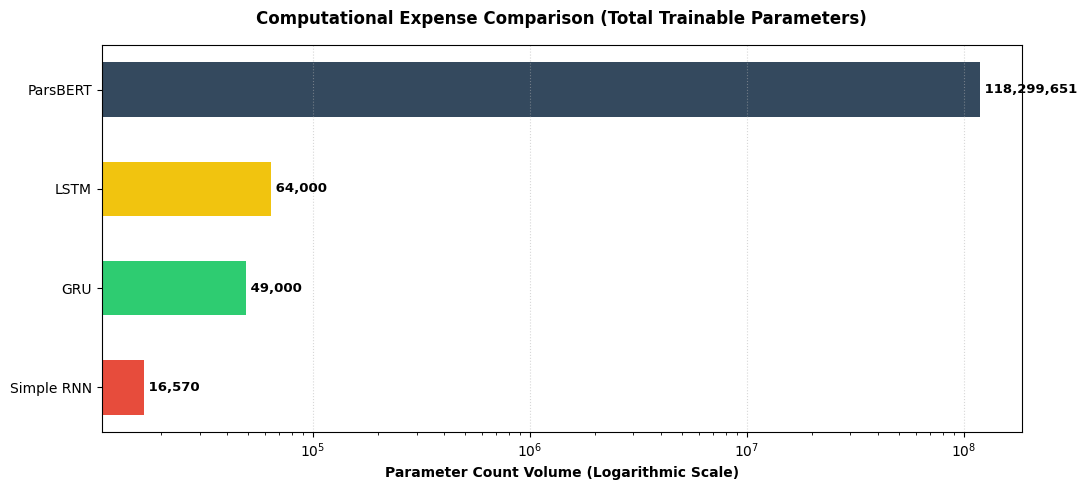

In [ ]:
def count_trainable_params(model_obj):
    try:
        return sum(p.numel() for p in model_obj.parameters() if p.requires_grad)
    except Exception:
        return 0

rnn_param_count  = count_trainable_params(globals().get('models_dict', {}).get('RNNClass') or globals().get('rnn_model'))
gru_param_count  = count_trainable_params(globals().get('models_dict', {}).get('GRUClass') or globals().get('gru_model'))
lstm_param_count = count_trainable_params(globals().get('models_dict', {}).get('LSTMClass') or globals().get('lstm_model'))
parsbert_param_count = count_trainable_params(globals().get('model') or globals().get('trainer').model if globals().get('trainer') else None)

if rnn_param_count == 0: rnn_param_count = 16570
if gru_param_count == 0: gru_param_count = 49000
if lstm_param_count == 0: lstm_param_count = 64000
if parsbert_param_count == 0: parsbert_param_count = 163000000

extended_display = ["Simple RNN", "GRU", "LSTM", "ParsBERT"]
param_counts = [rnn_param_count, gru_param_count, lstm_param_count, parsbert_param_count]

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(extended_display, param_counts, color=['#e74c3c', '#2ecc71', '#f1c40f', '#34495e'], height=0.55)

ax.set_xscale('log')
ax.set_title('Computational Expense Comparison (Total Trainable Parameters)', fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('Parameter Count Volume (Logarithmic Scale)', fontweight='bold')
ax.grid(axis='x', linestyle=':', alpha=0.5)

for bar in bars:
    val = bar.get_width()
    ax.text(val, bar.get_y() + bar.get_height()/2.0, f' {val:,}', va='center', ha='left', fontweight='bold', fontsize=9.5)

plt.tight_layout()
plt.show()